# Charlotte commercial lending indicators
## Exploratory data analysis | BankUnited market expansion

**Market:** Charlotte-Concord-Gastonia, NC-SC · **CBSA:** 16740  
**Supplied data:** 2015–2024 · **Analysis prepared:** October 25, 2026

**Business question:** Do the real estate business base, nonresidential construction activity,
and deposits booked outside main offices support further commercial banking investigation?

**Scope:** The six requested sector activity measures, real estate coverage fields,
and `sod_deposits_usd - sod_main_office_deposits_usd`. Construction coverage and both
source labels are used only to evaluate comparability. The attached CRA workbooks
are not used: they do not answer the project's larger-than-$1-million loan question.

**Read first:** These are market activity proxies. They do not measure addressable
loan dollars, corporate borrower counts, profitability, debt-service capacity,
commercial-only deposits, or credit quality. The supplied file ends in 2024;
this is a historical snapshot, not a current 2026 market assessment.

### How to run

1. Open this notebook in Jupyter, VS Code, or Google Colab.
2. Install the packages in the optional setup cell if needed.
3. Run all cells in order. A compressed copy of the supplied parquet is embedded,
   so the notebook runs without a separate download or network access after setup.
4. To analyze a refreshed file, set `DATA_PATH` below. Embedded data remain the default
   when no path is supplied. Reassess narrative assumptions before changing the market.

**Outputs:** twelve PNG charts, audit/metric/coverage/ranking CSVs, and an assumptions
and recommendations note. All tables and charts below are already executed.

**New in this update:** Section 9 adds the supplied `msa_naics_year.parquet` (2015–2023), four industry charts, coverage and reconciliation checks, and a commercial/corporate borrower-base interpretation. Both exact input files are embedded. The industry file has 387 CBSAs; the original market file has 393. No 2024 industry values are inferred.

In [2]:
from pathlib import Path
from io import BytesIO
import base64
import hashlib
import json
import platform
import warnings
import zlib

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 180, 'font.family': 'DejaVu Sans',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#475569', 'text.color': '#0f172a',
    'xtick.color': '#475569', 'ytick.color': '#475569',
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'font.size': 10,
})

# DATA_PATH = None # To use embedded original snapshot.
DATA_PATH = "../data/processed/msa_year.parquet" # To use the bundled external file.               
TARGET_CBSA = '16740'
BASE_YEAR = 2019
PREFERRED_END_YEAR = 2023
LATEST_YEAR = 2024
REFERENCE_COUNTIES = 11  # Diagnostic expectation inferred from supplied coverage fields.
OUTPUT_DIR = Path('outputs')
(OUTPUT_DIR / 'charts').mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'tables').mkdir(parents=True, exist_ok=True)
NAVY, TEAL, ORANGE = '#173b63', '#008b8b', '#d97706'
GREY, LIGHT = '#94a3b8', '#f1f5f9'
CHART_FILES = []

def save_chart(fig, filename):
    path = OUTPUT_DIR / 'charts' / filename
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    CHART_FILES.append(path)
    plt.show()
    plt.close(fig)

def safe_divide(numerator, denominator):
    return numerator / denominator.where(denominator.gt(0))

print('Python:', platform.python_version(), '| pandas:', pd.__version__,
      '| numpy:', np.__version__, '| matplotlib:', matplotlib.__version__)

Python: 3.12.3 | pandas: 3.0.6 | numpy: 2.4.6 | matplotlib: 3.11.2


In [28]:
# The payload is the exact original user-supplied file, compressed with zlib.
# Only the requested measures and related source/coverage metadata are analyzed.
ORIGINAL_SHA256 = '36fa8224eff62bb83aee98e27782543483bd31765c56d4493a20f24a5d3467ec'
EMBEDDED_PARQUET_ZLIB_BASE64 = '...'
if DATA_PATH is None:
    source_bytes = zlib.decompress(base64.b64decode(EMBEDDED_PARQUET_ZLIB_BASE64))
    assert hashlib.sha256(source_bytes).hexdigest() == ORIGINAL_SHA256
    input_origin = 'Embedded original msa_year.parquet'
else:
    source_path = Path(DATA_PATH).expanduser()
    if not source_path.is_file():
        raise FileNotFoundError(f'Cannot find {source_path.resolve()}')
    source_bytes = source_path.read_bytes()
    input_origin = str(source_path.resolve())
raw_df = pd.read_parquet(BytesIO(source_bytes))
provenance = {
    'input': input_origin, 'input_sha256': hashlib.sha256(source_bytes).hexdigest(),
    'input_bytes': len(source_bytes), 'analysis_date': '2026-10-25',
    'rows': len(raw_df), 'columns': len(raw_df.columns),
}
display(pd.DataFrame([provenance]))

,input,input_sha256,input_bytes,analysis_date,rows,columns
0,C:\Users\evand\Desktop\bankunited-market-expan...,36fa8224eff62bb83aee98e27782543483bd31765c56d4...,538060,2026-10-25,3930,45


## 1. Data dictionary and analytical choices

The `_usd` columns are assumed already converted to dollars by the pipeline.
Do **not** multiply payroll or deposits by 1,000 again without checking the upstream contract.

| Input fields | Analytical role | Important limit |
|---|---|---|
| `cre_real_estate_establishments_count` | Real estate business-location scale | Locations, not unique firms, corporate borrowers, property stock, or loan accounts |
| `cre_real_estate_employment_count` | Sector operating activity | Employment concept can differ between CBP and QCEW |
| `cre_real_estate_payroll_usd` | Nominal labor-payment flow | Not revenue, cash flow, profit, or deposits |
| `cre_real_estate_counties_reported_count` | Reported coverage diagnostic | A count field, not an economic opportunity metric |
| `cre_real_estate_qcew_fallback_counties_count` | Fallback coverage diagnostic | More fallback usage is not more attractive |
| `cre_nonres_construction_establishments_count` | Contractor-location scale | Not project count, floor area, or construction-loan volume |
| `cre_nonres_construction_employment_count` | Contractor operating scale | Does not identify project location or financing purpose |
| `cre_nonres_construction_payroll_usd` | Contractor labor-payment flow | Wage inflation can drive growth |
| `sod_deposits_usd`, `sod_main_office_deposits_usd` | Calculate deposits excluding main offices | Does not isolate locally originated or commercial deposits |
| Both `cre_*_source` labels and construction county-count fields | Validate source and coverage consistency | Labels do not prove identical NAICS definitions or county membership |

### Time windows

- **2019–2023:** preferred recent window because Charlotte's supplied source labels and
  reported/fallback county counts remain stable within each sector. Construction still
  combines CBP and QCEW; this is a consistency check, not full harmonization.
- **2024:** show the observed level and raw change separately. Both sectors switch to QCEW.
- **2015–2018:** retain for context; construction coverage counts vary.
- Dollars are nominal. No inflation adjustment, imputation, loan-volume extrapolation,
  composite attractiveness score, or causal regression is applied.

In [29]:


raw_df = pd.read_parquet(DATA_PATH)

SECTORS = {
    'cre_real_estate': 'Real estate',
    'cre_nonres_construction': 'Nonresidential construction',
}
MEASURE_NAMES = {
    'establishments_count': 'Establishments',
    'employment_count': 'Employment',
    'payroll_usd': 'Payroll (USD)',
}
SECTOR_COLS = [f'{s}_{m}' for s in SECTORS for m in MEASURE_NAMES]
COVERAGE_COLS = [f'{s}_{m}' for s in SECTORS for m in
                 ['counties_reported_count', 'qcew_fallback_counties_count']]
SOURCE_COLS = [f'{s}_source' for s in SECTORS]
DEPOSIT_COLS = ['sod_deposits_usd', 'sod_main_office_deposits_usd']
REQUIRED = ['cbsa_code', 'cbsa_title', 'year'] + SECTOR_COLS + COVERAGE_COLS + SOURCE_COLS + DEPOSIT_COLS
missing_columns = sorted(set(REQUIRED) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Required columns missing: {missing_columns}')

df = raw_df[REQUIRED].copy()
df['cbsa_code'] = df['cbsa_code'].astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(5)
df['year'] = pd.to_numeric(df['year'], errors='raise').astype(int)
NUMERIC_COLS = SECTOR_COLS + COVERAGE_COLS + DEPOSIT_COLS
for col in NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors='raise')
df = df.sort_values(['cbsa_code', 'year']).reset_index(drop=True)
duplicate_keys = df.duplicated(['cbsa_code', 'year'], keep=False)
if duplicate_keys.any():
    display(df.loc[duplicate_keys, ['cbsa_code', 'cbsa_title', 'year']])
    raise ValueError('Duplicate CBSA-year keys: resolve upstream before aggregation.')
if not df['cbsa_code'].eq(TARGET_CBSA).any():
    raise ValueError(f'Target CBSA {TARGET_CBSA} not found.')

df['non_main_office_deposits_usd'] = df['sod_deposits_usd'] - df['sod_main_office_deposits_usd']
df['main_office_share_pct'] = 100 * safe_divide(df['sod_main_office_deposits_usd'], df['sod_deposits_usd'])
for sector in SECTORS:
    df[f'{sector}_employees_per_establishment'] = safe_divide(
        df[f'{sector}_employment_count'], df[f'{sector}_establishments_count'])
    df[f'{sector}_payroll_per_employee_usd'] = safe_divide(
        df[f'{sector}_payroll_usd'], df[f'{sector}_employment_count'])
charlotte = df[df['cbsa_code'].eq(TARGET_CBSA)].copy().set_index('year').sort_index()
MARKET_TITLE = charlotte['cbsa_title'].iloc[-1]
required_years = set(range(BASE_YEAR, LATEST_YEAR + 1))
if not required_years.issubset(charlotte.index):
    raise ValueError(f'Missing target years: {sorted(required_years - set(charlotte.index))}')

audit = pd.DataFrame([
    ('Input rows', len(df), 'INFO'),
    ('Distinct CBSAs in supplied file', df['cbsa_code'].nunique(), 'INFO'),
    ('Duplicate CBSA-year rows', int(duplicate_keys.sum()), 'PASS'),
    ('Target observations', len(charlotte), 'INFO'),
    ('Target missing requested/source/coverage values',
     int(charlotte[NUMERIC_COLS + SOURCE_COLS].isna().sum().sum()), 'PASS' if not charlotte[NUMERIC_COLS + SOURCE_COLS].isna().any().any() else 'REVIEW'),
    ('Input negative numeric observations', int((df[NUMERIC_COLS] < 0).sum().sum()),
     'PASS' if not (df[NUMERIC_COLS] < 0).any().any() else 'REVIEW'),
    ('Input negative deposits excluding main offices', int(df['non_main_office_deposits_usd'].lt(0).sum()),
     'PASS' if not df['non_main_office_deposits_usd'].lt(0).any() else 'REVIEW'),
], columns=['Check', 'Result', 'Status'])
display(audit)
missingness = df.groupby('year')[NUMERIC_COLS].agg(lambda x: x.isna().sum())
display(Markdown('**Missing values across all CBSAs by year (not imputed):**'))
display(missingness)
if (df[NUMERIC_COLS] < 0).any().any() or df['non_main_office_deposits_usd'].lt(0).any():
    raise ValueError('Unexpected negative input values: resolve before continuing.')
audit.to_csv(OUTPUT_DIR / 'tables/data_audit.csv', index=False)
missingness.to_csv(OUTPUT_DIR / 'tables/all_cbsa_missingness.csv')

,Check,Result,Status
0,Input rows,3930,INFO
1,Distinct CBSAs in supplied file,393,INFO
2,Duplicate CBSA-year rows,0,PASS
3,Target observations,10,INFO
4,Target missing requested/source/coverage values,0,PASS
5,Input negative numeric observations,0,PASS
6,Input negative deposits excluding main offices,0,PASS


**Missing values across all CBSAs by year (not imputed):**

,cre_real_estate_establishments_count,cre_real_estate_employment_count,cre_real_estate_payroll_usd,cre_nonres_construction_establishments_count,cre_nonres_construction_employment_count,cre_nonres_construction_payroll_usd,cre_real_estate_counties_reported_count,cre_real_estate_qcew_fallback_counties_count,cre_nonres_construction_counties_reported_count,cre_nonres_construction_qcew_fallback_counties_count,sod_deposits_usd,sod_main_office_deposits_usd
year,,,,,,,,,,,,
2015,5,5,5,5,8,8,5,5,5,5,5,5
2016,5,5,5,5,10,10,5,5,5,5,5,5
2017,5,5,5,5,9,9,5,5,5,5,5,5
2018,5,5,5,5,8,8,5,5,5,5,5,5
2019,5,5,5,5,6,6,5,5,5,5,5,5
2020,5,5,5,5,5,5,5,5,5,5,5,5
2021,5,5,5,5,6,6,5,5,5,5,5,5
2022,0,0,0,0,2,2,0,0,0,0,5,5
2023,0,0,0,0,1,1,0,0,0,0,0,0


## 2. Coverage and source breaks

The counts below are retained exactly as supplied. The diagnostic reference of 11 counties
is inferred from this file and is not an independently validated OMB crosswalk.
Reported and fallback counts are plotted separately; we do not assume their sum proves
complete, non-overlapping county coverage.

**Why the 2024 break matters:** Census CBP employment refers to the pay period including
March 12; QCEW annual employment averages monthly employment. An observed change between
the two can combine economic change with measurement change. Confirm the pipeline's exact
QCEW aggregation, ownership scope, NAICS codes, geographic crosswalk, and payroll mapping.

Official methodology: [Census CBP](https://www.census.gov/programs-surveys/cbp.html),
[BLS QCEW annual definitions](https://www.bls.gov/cew/publications/employment-and-wages-annual-averages/2025/home.htm).

,cre_real_estate_counties_reported_count,cre_real_estate_qcew_fallback_counties_count,cre_nonres_construction_counties_reported_count,cre_nonres_construction_qcew_fallback_counties_count,cre_real_estate_source,cre_nonres_construction_source
year,,,,,,
2015,11.00,0.00,9.00,0.00,CBP,CBP
2016,11.00,0.00,9.00,0.00,CBP,CBP
2017,11.00,0.00,10.00,0.00,CBP,CBP
2018,11.00,0.00,11.00,0.00,CBP,CBP
2019,11.00,0.00,10.00,1.00,CBP,CBP+QCEW
2020,11.00,0.00,10.00,1.00,CBP,CBP+QCEW
2021,11.00,0.00,10.00,1.00,CBP,CBP+QCEW
2022,11.00,0.00,10.00,1.00,CBP,CBP+QCEW
2023,11.00,0.00,10.00,1.00,CBP,CBP+QCEW


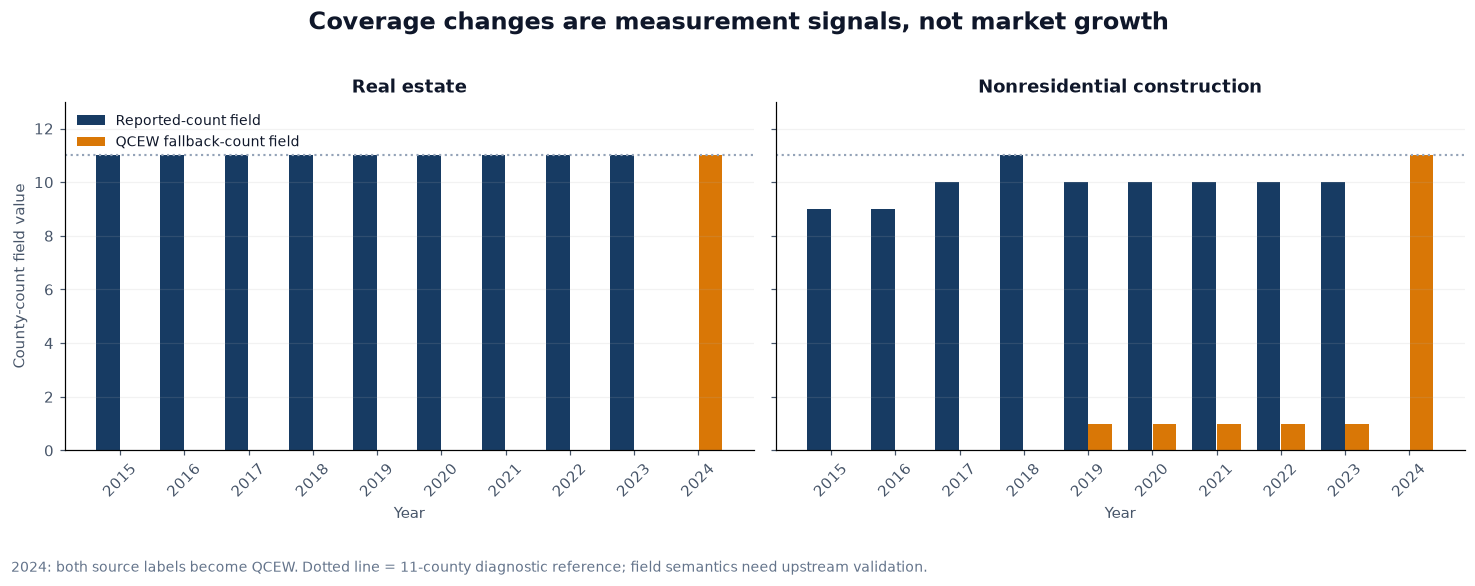

In [4]:
coverage = charlotte[COVERAGE_COLS + SOURCE_COLS].copy()
display(coverage)
coverage.to_csv(OUTPUT_DIR / 'tables/charlotte_coverage_and_sources.csv')

# Flag any adjacent-year source-label OR county-count change. Counts with unchanged
# totals can still hide changing county membership; this diagnostic cannot detect that.
interval_flags = pd.DataFrame(False, index=charlotte.index, columns=list(SECTORS))
for sector in SECTORS:
    check = [f'{sector}_source', f'{sector}_counties_reported_count',
             f'{sector}_qcew_fallback_counties_count']
    interval_flags[sector] = charlotte[check].ne(charlotte[check].shift()).any(axis=1)
interval_flags.iloc[0] = False

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7), sharey=True)
for ax, (sector, label) in zip(axes, SECTORS.items()):
    x = np.arange(len(charlotte))
    ax.bar(x - .19, charlotte[f'{sector}_counties_reported_count'], width=.37, color=NAVY, label='Reported-count field')
    ax.bar(x + .19, charlotte[f'{sector}_qcew_fallback_counties_count'], width=.37, color=ORANGE, label='QCEW fallback-count field')
    ax.axhline(REFERENCE_COUNTIES, color=GREY, linestyle=':', linewidth=1.4)
    ax.set_xticks(x, charlotte.index.astype(str), rotation=45)
    ax.set_title(label)
    ax.set_xlabel('Year')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(0, max(REFERENCE_COUNTIES, charlotte[COVERAGE_COLS].max().max()) + 2)
    ax.grid(axis='y', alpha=.16)
axes[0].set_ylabel('County-count field value')
axes[0].legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle('Coverage changes are measurement signals, not market growth', fontsize=16, fontweight='bold', y=1.02)
fig.text(.01, -.065, '2024: both source labels become QCEW. Dotted line = 11-county diagnostic reference; field semantics need upstream validation.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '01_coverage_and_source_breaks.png')

## 3. Levels, recent growth, and descriptive statistics

For an interval of $n$ years:

$$\text{total growth} = (x_{end}/x_{start}-1)\times100$$
$$\text{CAGR} = [(x_{end}/x_{start})^{1/n}-1]\times100$$

Year-over-year growth is computed only for consecutive years, with no forward filling.
Missing or nonpositive denominators produce missing derived values. The 2024 change
is retained as a raw observation and flagged when source or coverage changes.

In [5]:
ANALYSIS_COLS = SECTOR_COLS + DEPOSIT_COLS + ['non_main_office_deposits_usd']
LABELS = {f'{s}_{m}': f'{label}: {MEASURE_NAMES[m]}' for s, label in SECTORS.items() for m in MEASURE_NAMES}
LABELS.update({
    'sod_deposits_usd': 'Total deposits',
    'sod_main_office_deposits_usd': 'Main-office deposits',
    'non_main_office_deposits_usd': 'Deposits excluding main offices',
})
yoy = charlotte[ANALYSIS_COLS].pct_change(fill_method=None).mul(100)
consecutive = charlotte.index.to_series().diff().eq(1)
yoy.loc[~consecutive] = np.nan
yoy = yoy.where(charlotte[ANALYSIS_COLS].shift().gt(0))

rows = []
for col in ANALYSIS_COLS:
    start, end, latest = charlotte.loc[BASE_YEAR, col], charlotte.loc[PREFERRED_END_YEAR, col], charlotte.loc[LATEST_YEAR, col]
    sector = next((s for s in SECTORS if col.startswith(s + '_')), None)
    stable = True
    if sector:
        ck = [f'{sector}_source', f'{sector}_counties_reported_count', f'{sector}_qcew_fallback_counties_count']
        stable = charlotte.loc[BASE_YEAR:PREFERRED_END_YEAR, ck].notna().all().all() and charlotte.loc[BASE_YEAR:PREFERRED_END_YEAR, ck].nunique().eq(1).all()
    rows.append({
        'metric': col, 'label': LABELS[col], f'value_{BASE_YEAR}': start,
        f'value_{PREFERRED_END_YEAR}': end, f'value_{LATEST_YEAR}': latest,
        'preferred_total_growth_pct': 100 * (end / start - 1) if start > 0 else np.nan,
        'preferred_cagr_pct': 100 * ((end / start) ** (1 / (PREFERRED_END_YEAR - BASE_YEAR)) - 1) if start > 0 and end > 0 else np.nan,
        'preferred_source_and_count_labels_stable': bool(stable),
        'latest_yoy_raw_pct': yoy.loc[LATEST_YEAR, col],
        'latest_source_or_coverage_break': bool(interval_flags.loc[LATEST_YEAR, sector]) if sector else False,
    })
growth_summary = pd.DataFrame(rows)
display(growth_summary.drop(columns='metric'))
display(Markdown('**Annual levels in original units:**'))
display(charlotte[ANALYSIS_COLS].rename(columns=LABELS))
display(Markdown('**Descriptive statistics across all ten target years (mixed-source history; not a forecast):**'))
descriptive = charlotte[ANALYSIS_COLS].describe().T
display(descriptive)
charlotte.to_csv(OUTPUT_DIR / 'tables/charlotte_annual_indicators.csv')
growth_summary.to_csv(OUTPUT_DIR / 'tables/charlotte_growth_summary.csv', index=False)
yoy.to_csv(OUTPUT_DIR / 'tables/charlotte_yoy_raw_pct.csv')
descriptive.to_csv(OUTPUT_DIR / 'tables/charlotte_descriptive_statistics.csv')

,label,value_2019,value_2023,value_2024,preferred_total_growth_pct,preferred_cagr_pct,preferred_source_and_count_labels_stable,latest_yoy_raw_pct,latest_source_or_coverage_break
0,Real estate: Establishments,"3,677.00","4,479.00","5,006.00",21.81,5.06,True,11.77,True
1,Real estate: Employment,"13,190.00","16,536.00","16,371.00",25.37,5.81,True,-1.00,True
2,Real estate: Payroll (USD),"840,855,000.00","1,163,068,000.00","1,452,713,089.00",38.32,8.45,True,24.90,True
3,Nonresidential construction: Establishments,340.00,376.00,542.00,10.59,2.55,True,44.15,True
4,Nonresidential construction: Employment,"4,468.00","5,498.00","6,184.00",23.05,5.32,True,12.48,True
5,Nonresidential construction: Payroll (USD),"353,477,000.00","543,880,096.00","685,187,817.00",53.87,11.37,True,25.98,True
6,Total deposits,"206,293,961,000.00","382,551,783,000.00","457,313,881,000.00",85.44,16.69,True,19.54,False
7,Main-office deposits,"145,134,630,000.00","301,465,724,000.00","383,878,513,000.00",107.71,20.05,True,27.34,False
8,Deposits excluding main offices,"61,159,331,000.00","81,086,059,000.00","73,435,368,000.00",32.58,7.31,True,-9.44,False


**Annual levels in original units:**

,Real estate: Establishments,Real estate: Employment,Real estate: Payroll (USD),Nonresidential construction: Establishments,Nonresidential construction: Employment,Nonresidential construction: Payroll (USD),Total deposits,Main-office deposits,Deposits excluding main offices
year,,,,,,,,,
2015,"2,670.00","10,270.00","596,521,000.00",329.00,"3,305.00","215,797,000.00","216,453,394,000.00","156,562,581,000.00","59,890,813,000.00"
2016,"2,919.00","11,156.00","650,093,000.00",350.00,"3,724.00","242,213,000.00","201,093,756,000.00","146,453,545,000.00","54,640,211,000.00"
2017,"3,304.00","11,893.00","700,511,000.00",345.00,"4,400.00","320,039,000.00","217,333,913,000.00","158,698,482,000.00","58,635,431,000.00"
2018,"3,509.00","12,725.00","763,818,000.00",338.00,"4,504.00","338,566,000.00","215,485,671,000.00","155,806,907,000.00","59,678,764,000.00"
2019,"3,677.00","13,190.00","840,855,000.00",340.00,"4,468.00","353,477,000.00","206,293,961,000.00","145,134,630,000.00","61,159,331,000.00"
2020,"3,895.00","13,704.00","888,890,000.00",328.00,"4,847.00","388,159,000.00","336,816,900,000.00","263,465,758,000.00","73,351,142,000.00"
2021,"4,166.00","13,856.00","973,657,000.00",339.00,"4,715.00","419,609,000.00","315,760,219,000.00","226,740,120,000.00","89,020,099,000.00"
2022,"4,364.00","15,385.00","1,096,923,000.00",368.00,"5,135.00","492,714,130.00","336,499,725,000.00","248,707,003,000.00","87,792,722,000.00"
2023,"4,479.00","16,536.00","1,163,068,000.00",376.00,"5,498.00","543,880,096.00","382,551,783,000.00","301,465,724,000.00","81,086,059,000.00"


**Descriptive statistics across all ten target years (mixed-source history; not a forecast):**

,count,mean,std,min,25%,50%,75%,max
cre_real_estate_establishments_count,10.00,"3,798.90",728.43,"2,670.00","3,355.25","3,786.00","4,314.50","5,006.00"
cre_real_estate_employment_count,10.00,"13,508.60","2,118.36","10,270.00","12,101.00","13,447.00","15,002.75","16,536.00"
cre_real_estate_payroll_usd,10.00,"912,704,908.90","265,372,354.61","596,521,000.00","716,337,750.00","864,872,500.00","1,066,106,500.00","1,452,713,089.00"
cre_nonres_construction_establishments_count,10.00,365.50,63.92,328.00,338.25,342.50,363.50,542.00
cre_nonres_construction_employment_count,10.00,"4,678.00",825.03,"3,305.00","4,417.00","4,609.50","5,063.00","6,184.00"
cre_nonres_construction_payroll_usd,10.00,"399,964,204.30","142,327,463.67","215,797,000.00","324,670,750.00","370,818,000.00","474,437,847.50","685,187,817.00"
sod_deposits_usd,10.00,"288,560,320,300.00","89,882,358,815.77","201,093,756,000.00","215,727,601,750.00","266,547,066,000.00","336,737,606,250.00","457,313,881,000.00"
sod_main_office_deposits_usd,10.00,"218,691,326,300.00","81,070,160,556.89","145,134,630,000.00","155,995,825,500.00","192,719,301,000.00","259,776,069,250.00","383,878,513,000.00"
non_main_office_deposits_usd,10.00,"69,868,994,000.00","12,806,524,621.75","54,640,211,000.00","59,731,776,250.00","67,255,236,500.00","79,173,386,250.00","89,020,099,000.00"


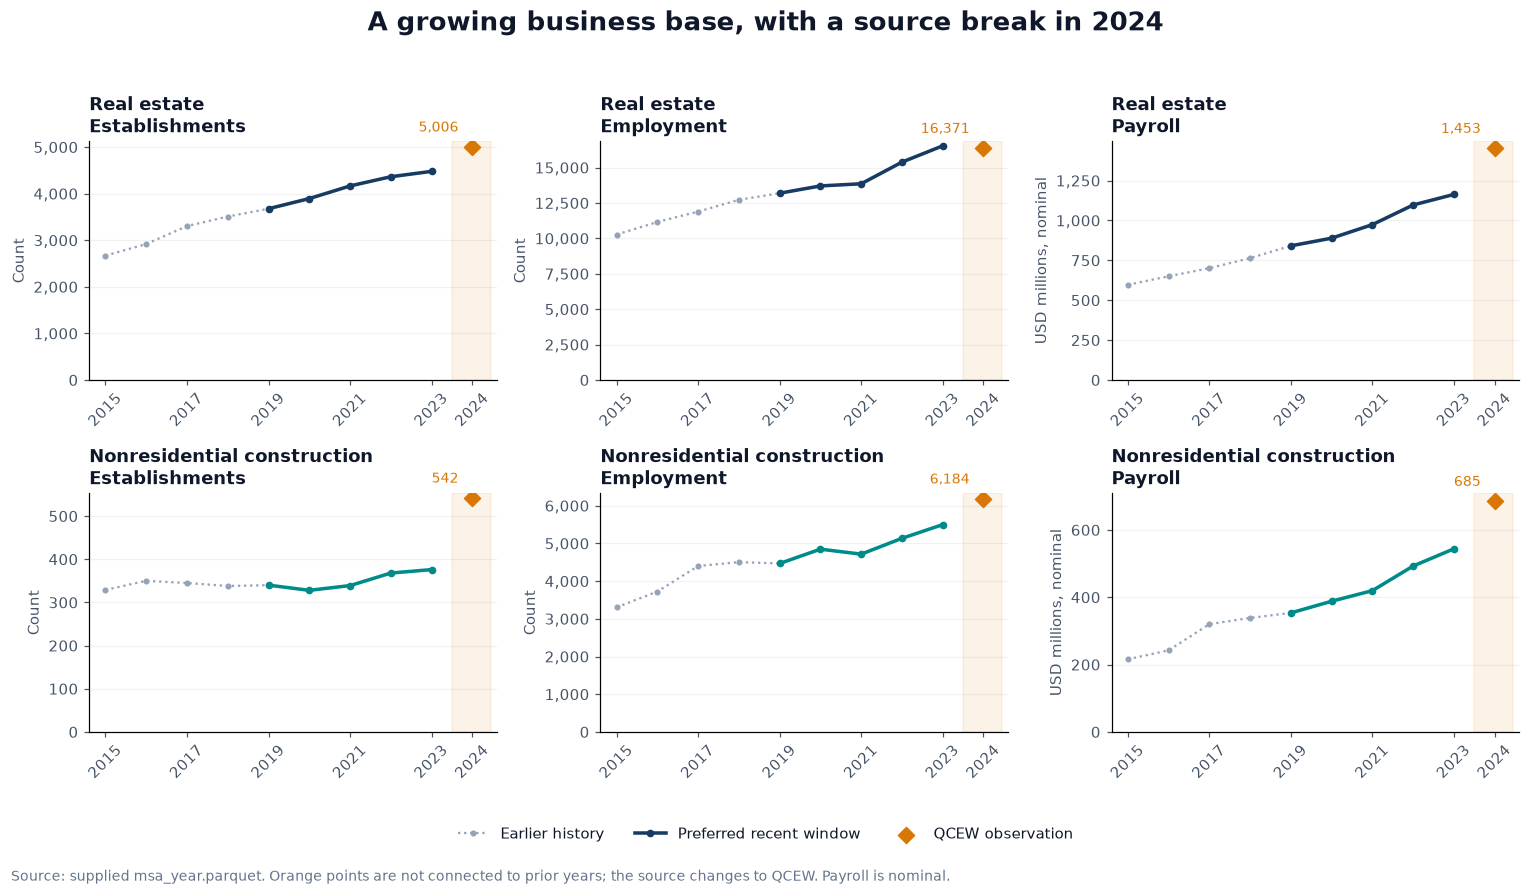

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for row, (sector, sector_label) in enumerate(SECTORS.items()):
    for j, (measure, measure_label) in enumerate(MEASURE_NAMES.items()):
        ax = axes[row, j]
        col = f'{sector}_{measure}'
        scale = 1e6 if measure == 'payroll_usd' else 1
        prior = charlotte.loc[:BASE_YEAR, col] / scale
        preferred = charlotte.loc[BASE_YEAR:PREFERRED_END_YEAR, col] / scale
        ax.plot(prior.index, prior, ':', color=GREY, marker='o', ms=3, label='Earlier history')
        ax.plot(preferred.index, preferred, color=NAVY if row == 0 else TEAL, marker='o', lw=2.3, ms=4, label='Preferred recent window')
        val = charlotte.loc[LATEST_YEAR, col] / scale
        ax.scatter([LATEST_YEAR], [val], color=ORANGE, marker='D', s=55, zorder=4, label='QCEW observation')
        ax.axvspan(PREFERRED_END_YEAR + .5, LATEST_YEAR + .45, color=ORANGE, alpha=.09)
        ax.annotate(f'{val:,.0f}', (LATEST_YEAR, val), xytext=(-9, 10), textcoords='offset points', ha='right', fontsize=9, color=ORANGE)
        ax.set_title(f'{sector_label}\n{measure_label.replace(" (USD)", "")}', loc='left')
        ax.set_ylabel('USD millions, nominal' if scale == 1e6 else 'Count')
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))
        ax.set_xticks([2015, 2017, BASE_YEAR, 2021, PREFERRED_END_YEAR, LATEST_YEAR])
        ax.tick_params(axis='x', rotation=45)
        ax.set_xlim(charlotte.index.min() - .4, LATEST_YEAR + .6)
        ax.set_ylim(bottom=0)
        ax.grid(axis='y', alpha=.17)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(.5, -.015))
fig.suptitle('A growing business base, with a source break in 2024', fontsize=17, fontweight='bold', y=1.01)
fig.text(.01, -.045, 'Source: supplied msa_year.parquet. Orange points are not connected to prior years; the source changes to QCEW. Payroll is nominal.', fontsize=9, color='#64748b')
fig.tight_layout(rect=(0, .055, 1, .98))
save_chart(fig, '02_sector_activity_levels.png')

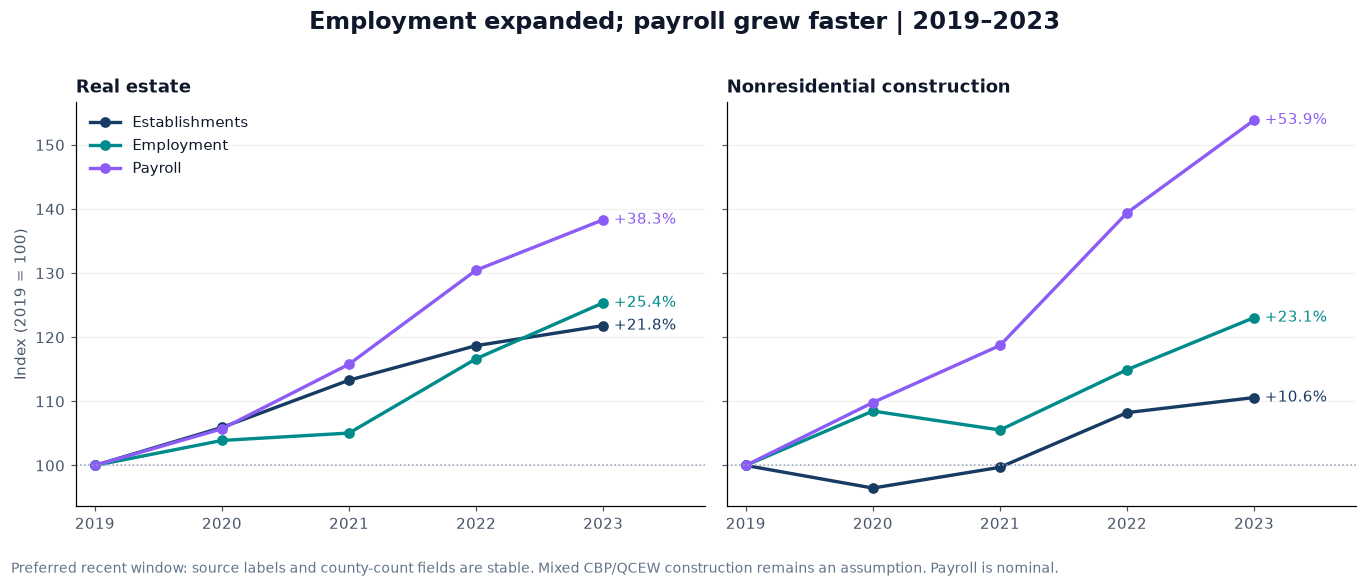

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
colors = [NAVY, TEAL, '#8b5cf6']
for ax, (sector, sector_label) in zip(axes, SECTORS.items()):
    for (measure, measure_label), color in zip(MEASURE_NAMES.items(), colors):
        col = f'{sector}_{measure}'
        series = 100 * charlotte.loc[BASE_YEAR:PREFERRED_END_YEAR, col] / charlotte.loc[BASE_YEAR, col]
        ax.plot(series.index, series, marker='o', lw=2.2, label=measure_label.replace(' (USD)', ''), color=color)
        ax.annotate(f'+{series.iloc[-1] - 100:.1f}%', (PREFERRED_END_YEAR, series.iloc[-1]), xytext=(7, 0), textcoords='offset points', color=color, fontsize=10, va='center')
    ax.set_title(sector_label, loc='left')
    ax.set_xticks(range(BASE_YEAR, PREFERRED_END_YEAR + 1))
    ax.set_xlim(BASE_YEAR - .15, PREFERRED_END_YEAR + .8)
    ax.axhline(100, lw=1, color=GREY, linestyle=':')
    ax.grid(axis='y', alpha=.16)
axes[0].set_ylabel(f'Index ({BASE_YEAR} = 100)')
axes[0].legend(frameon=False, loc='upper left')
fig.suptitle(f'Employment expanded; payroll grew faster | {BASE_YEAR}–{PREFERRED_END_YEAR}', fontsize=16, fontweight='bold', y=1.02)
fig.text(.01, -.045, 'Preferred recent window: source labels and county-count fields are stable. Mixed CBP/QCEW construction remains an assumption. Payroll is nominal.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '03_preferred_window_growth.png')

### What the sector indicators suggest

The tables below calculate operating scale without treating establishments as unique firms.
Payroll divided by employment is a **descriptive ratio**, not a measured average salary:
CBP annual payroll is divided by March employment, while QCEW may use annual averages.

Growing employment and payroll support investigation of working-capital, equipment,
treasury, and relationship opportunities. They do not establish that a business seeks
external financing or qualifies for a loan above $1 million.

In [8]:
operating_cols = [f'{s}_{m}' for s in SECTORS for m in
                  ['employees_per_establishment', 'payroll_per_employee_usd']]
operating_scale = charlotte.loc[[BASE_YEAR, PREFERRED_END_YEAR, LATEST_YEAR], operating_cols]
display(operating_scale)
operating_scale.to_csv(OUTPUT_DIR / 'tables/charlotte_operating_scale_ratios.csv')

,cre_real_estate_employees_per_establishment,cre_real_estate_payroll_per_employee_usd,cre_nonres_construction_employees_per_establishment,cre_nonres_construction_payroll_per_employee_usd
year,,,,
2019,3.59,"63,749.43",13.14,"79,113.03"
2023,3.69,"70,335.51",14.62,"98,923.26"
2024,3.27,"88,736.98",11.41,"110,800.10"


## 4. Deposit composition and direction

$$\text{deposits excluding main offices} = \text{total SOD deposits} - \text{main-office SOD deposits}$$

SOD is a June 30 balance snapshot, not annual deposit inflow. Subtraction reduces main-office
booking effects but also removes genuine deposits booked at those offices; remaining branch
deposits can still have booking effects. The result is neither commercial-only nor proven
locally generated deposits. No cause of a balance change is assigned from this aggregate file.

Methodology: [FDIC Summary of Deposits](https://www.fdic.gov/bank-financial-reports/summary-deposits).

,sod_deposits_usd,sod_main_office_deposits_usd,non_main_office_deposits_usd,main_office_share_pct,non_main_office_yoy_pct
year,,,,,
2015,"216,453,394,000.00","156,562,581,000.00","59,890,813,000.00",72.33,NaN
2016,"201,093,756,000.00","146,453,545,000.00","54,640,211,000.00",72.83,-8.77
2017,"217,333,913,000.00","158,698,482,000.00","58,635,431,000.00",73.02,7.31
2018,"215,485,671,000.00","155,806,907,000.00","59,678,764,000.00",72.30,1.78
2019,"206,293,961,000.00","145,134,630,000.00","61,159,331,000.00",70.35,2.48
2020,"336,816,900,000.00","263,465,758,000.00","73,351,142,000.00",78.22,19.93
2021,"315,760,219,000.00","226,740,120,000.00","89,020,099,000.00",71.81,21.36
2022,"336,499,725,000.00","248,707,003,000.00","87,792,722,000.00",73.91,-1.38
2023,"382,551,783,000.00","301,465,724,000.00","81,086,059,000.00",78.80,-7.64


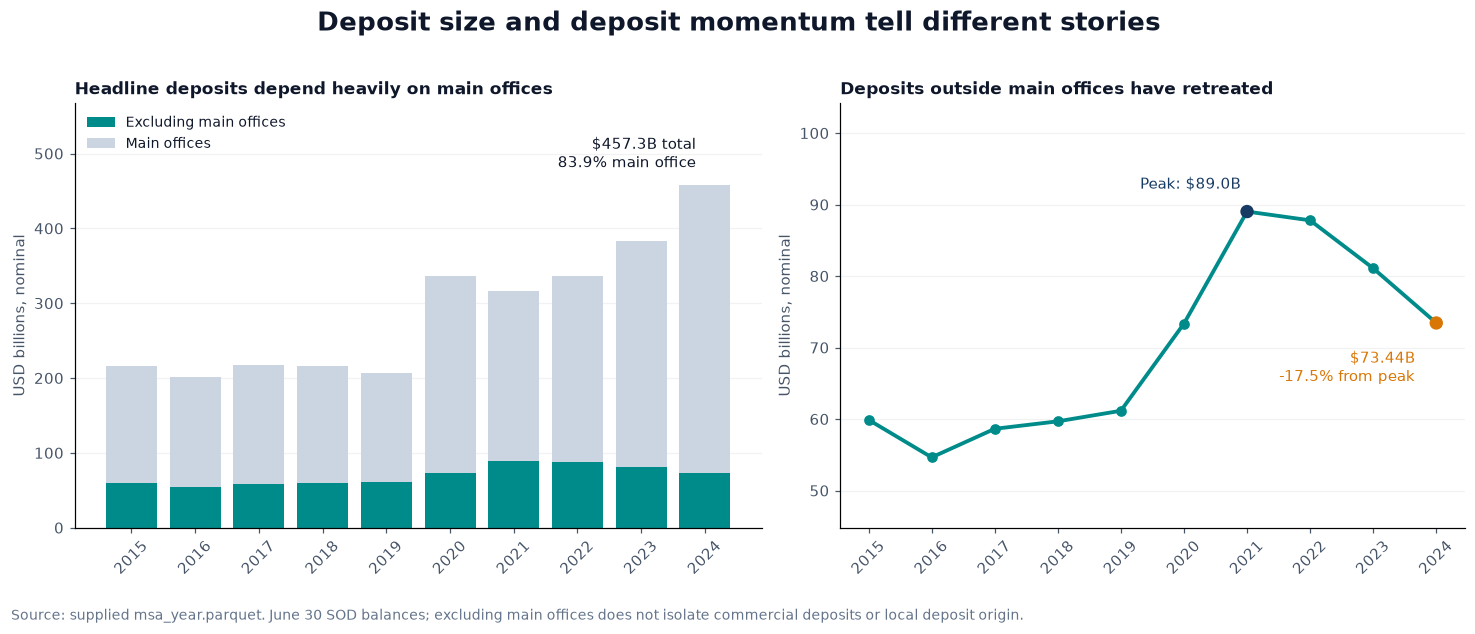

In [9]:
deposit_table = charlotte[DEPOSIT_COLS + ['non_main_office_deposits_usd', 'main_office_share_pct']].copy()
deposit_table['non_main_office_yoy_pct'] = yoy['non_main_office_deposits_usd']
display(deposit_table)
deposit_table.to_csv(OUTPUT_DIR / 'tables/charlotte_deposits.csv')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
years = charlotte.index.to_numpy()
non_main = charlotte['non_main_office_deposits_usd'] / 1e9
main = charlotte['sod_main_office_deposits_usd'] / 1e9
axes[0].bar(years, non_main, color=TEAL, label='Excluding main offices')
axes[0].bar(years, main, bottom=non_main, color='#cbd5e1', label='Main offices')
axes[0].set_title('Headline deposits depend heavily on main offices', loc='left', fontsize=11)
axes[0].set_ylabel('USD billions, nominal')
axes[0].legend(frameon=False, fontsize=9, loc='upper left')
total_last = charlotte.loc[LATEST_YEAR, 'sod_deposits_usd'] / 1e9
share_last = charlotte.loc[LATEST_YEAR, 'main_office_share_pct']
axes[0].annotate(f'${total_last:,.1f}B total\n{share_last:.1f}% main office', (LATEST_YEAR, total_last), xytext=(-6, 12), textcoords='offset points', ha='right', fontsize=10)
axes[0].set_ylim(0, total_last * 1.24)
axes[1].plot(years, non_main, color=TEAL, marker='o', lw=2.5)
peak_year = non_main.idxmax()
peak_change = 100 * (non_main.loc[LATEST_YEAR] / non_main.loc[peak_year] - 1)
axes[1].scatter([peak_year, LATEST_YEAR], [non_main.loc[peak_year], non_main.loc[LATEST_YEAR]], color=[NAVY, ORANGE], zorder=5, s=60)
axes[1].annotate(f'Peak: ${non_main.loc[peak_year]:.1f}B', (peak_year, non_main.loc[peak_year]), xytext=(-70, 15), textcoords='offset points', color=NAVY)
axes[1].annotate(f'${non_main.loc[LATEST_YEAR]:.2f}B\n{peak_change:+.1f}% from peak', (LATEST_YEAR, non_main.loc[LATEST_YEAR]), xytext=(-14, -38), textcoords='offset points', ha='right', color=ORANGE)
axes[1].set_title('Deposits outside main offices have retreated', loc='left', fontsize=11)
axes[1].set_ylabel('USD billions, nominal')
axes[1].set_ylim(non_main.min() * .82, non_main.max() * 1.17)
for ax in axes:
    ax.set_xticks(years, years.astype(str), rotation=45)
    ax.grid(axis='y', alpha=.16)
    ax.set_axisbelow(True)
fig.suptitle('Deposit size and deposit momentum tell different stories', fontsize=17, fontweight='bold', y=1.02)
fig.text(.01, -.045, 'Source: supplied msa_year.parquet. June 30 SOD balances; excluding main offices does not isolate commercial deposits or local deposit origin.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '04_deposit_composition_and_momentum.png')

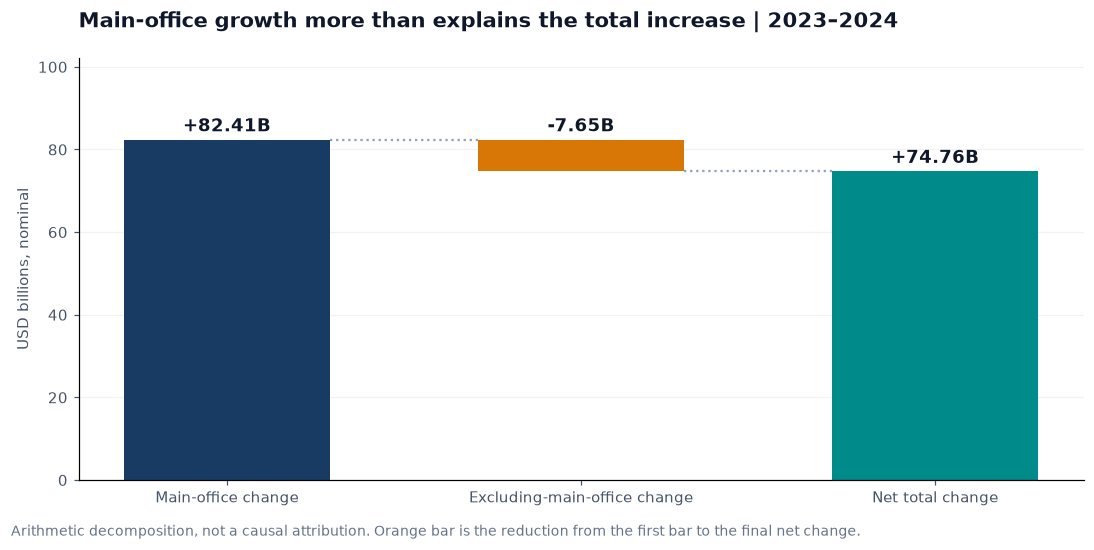

In [10]:
delta_main = (charlotte.loc[LATEST_YEAR, 'sod_main_office_deposits_usd'] - charlotte.loc[LATEST_YEAR - 1, 'sod_main_office_deposits_usd']) / 1e9
delta_nonmain = (charlotte.loc[LATEST_YEAR, 'non_main_office_deposits_usd'] - charlotte.loc[LATEST_YEAR - 1, 'non_main_office_deposits_usd']) / 1e9
delta_total = (charlotte.loc[LATEST_YEAR, 'sod_deposits_usd'] - charlotte.loc[LATEST_YEAR - 1, 'sod_deposits_usd']) / 1e9
assert np.isclose(delta_main + delta_nonmain, delta_total)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(0, delta_main, color=NAVY, width=.58)
ax.bar(1, abs(delta_nonmain), bottom=min(delta_main, delta_main + delta_nonmain), color=ORANGE, width=.58)
ax.plot([.29, .71], [delta_main, delta_main], color=GREY, linestyle=':')
ax.plot([1.29, 1.71], [delta_total, delta_total], color=GREY, linestyle=':')
ax.bar(2, delta_total, color=TEAL, width=.58)
for x, delta, top in [(0, delta_main, delta_main), (1, delta_nonmain, max(delta_main, delta_main + delta_nonmain)), (2, delta_total, delta_total)]:
    ax.text(x, top + 2, f'{delta:+.2f}B', ha='center', fontweight='bold', fontsize=12)
ax.set_xticks([0, 1, 2], ['Main-office change', 'Excluding-main-office change', 'Net total change'])
ax.set_ylabel('USD billions, nominal')
ax.set_ylim(0, max(delta_main, delta_total) * 1.24)
ax.grid(axis='y', alpha=.16)
ax.set_axisbelow(True)
ax.set_title(f'Main-office growth more than explains the total increase | {LATEST_YEAR - 1}–{LATEST_YEAR}', fontsize=14, loc='left', pad=20)
fig.text(.01, -.025, 'Arithmetic decomposition, not a causal attribution. Orange bar is the reduction from the first bar to the final net change.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '05_deposit_change_bridge.png')

## 5. Year-over-year change with comparability flags

Gray cells with an asterisk display raw changes spanning source-label or coverage-count
changes. They are excluded from the heatmap color scale. The absence of a flag does not
prove full comparability: county identities, NAICS definitions, and deposit booking rules
are not available in this file.

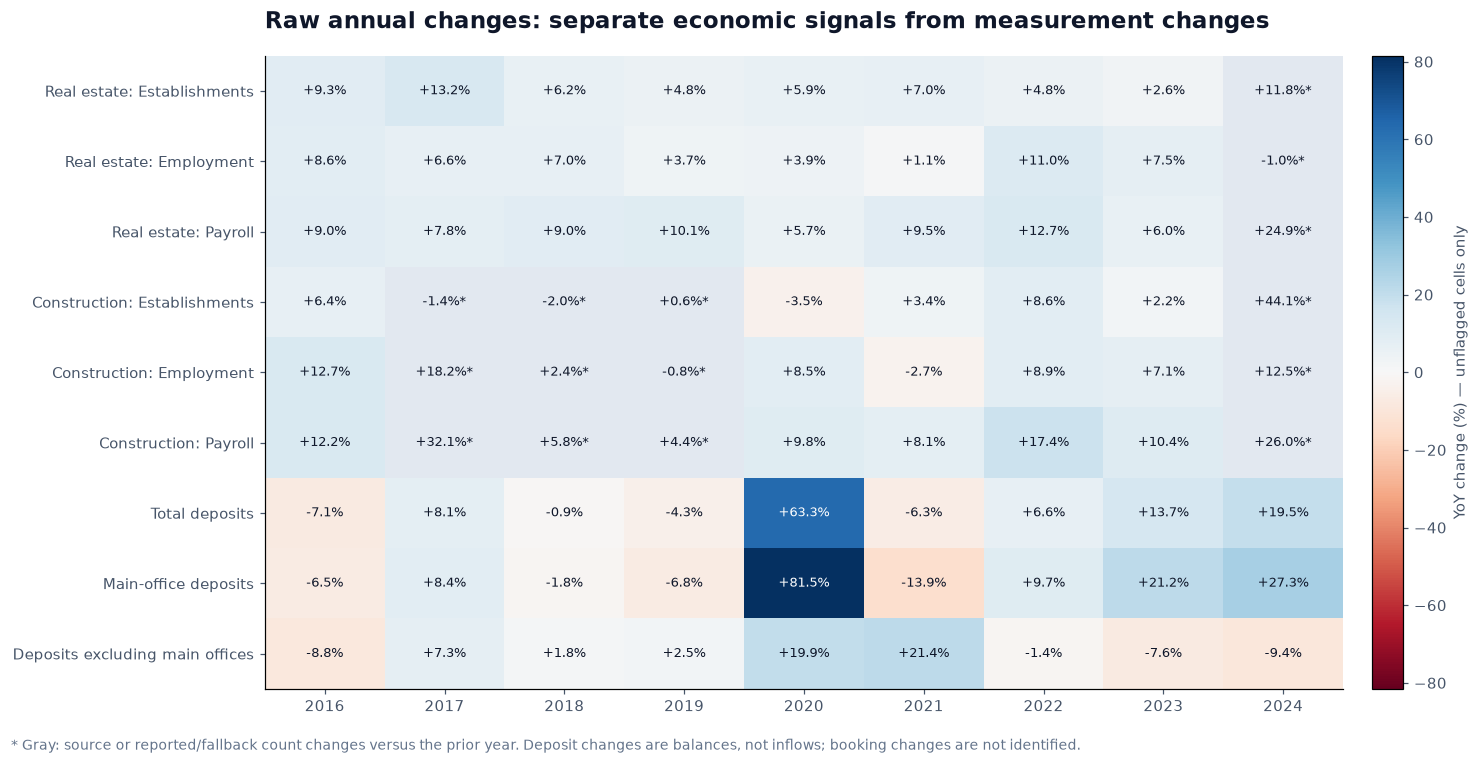

In [11]:
heat_cols = ANALYSIS_COLS
heat_years = charlotte.index[1:]
matrix = yoy.loc[heat_years, heat_cols].T
flagged = pd.DataFrame(False, index=heat_cols, columns=heat_years)
for col in SECTOR_COLS:
    sector = next(s for s in SECTORS if col.startswith(s + '_'))
    flagged.loc[col] = interval_flags.loc[heat_years, sector].to_numpy()
values = matrix.to_numpy(dtype=float)
mask = flagged.to_numpy() | ~np.isfinite(values)
scale = max(1, float(np.nanmax(np.abs(np.where(mask, np.nan, values)))))
cmap = plt.get_cmap('RdBu').copy()
cmap.set_bad('#e2e8f0')
fig, ax = plt.subplots(figsize=(13.5, 6.7))
im = ax.imshow(np.ma.array(values, mask=mask), cmap=cmap, vmin=-scale, vmax=scale, aspect='auto')
ax.set_xticks(range(len(heat_years)), heat_years)
short_names = [LABELS[c].replace('Nonresidential construction', 'Construction').replace(' (USD)', '') for c in heat_cols]
ax.set_yticks(range(len(heat_cols)), short_names)
for i in range(len(heat_cols)):
    for j in range(len(heat_years)):
        v = values[i, j]
        text = 'NA' if not np.isfinite(v) else f'{v:+.1f}%' + ('*' if flagged.iloc[i, j] else '')
        color = '#0f172a' if mask[i, j] or abs(v) < scale * .58 else 'white'
        ax.text(j, i, text, ha='center', va='center', fontsize=8.5, color=color)
ax.set_title('Raw annual changes: separate economic signals from measurement changes', fontsize=15, loc='left', pad=18)
cbar = fig.colorbar(im, ax=ax, fraction=.028, pad=.025)
cbar.set_label('YoY change (%) — unflagged cells only')
fig.text(.01, -.025, '* Gray: source or reported/fallback count changes versus the prior year. Deposit changes are balances, not inflows; booking changes are not identified.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '06_yoy_change_with_quality_flags.png')
flagged.T.to_csv(OUTPUT_DIR / 'tables/charlotte_yoy_source_coverage_flags.csv')

## 6. Peer scale: where Charlotte sits in this supplied dataset

The comparison universe is the **393 distinct CBSAs in the supplied file**, including Charlotte, not an independently
verified current universe of U.S. MSAs or a business-model-matched banking peer group.
Ranks use only nonmissing, nonnegative values in the same year; sample size varies by metric.
Ties receive the smallest rank (`method='min'`). Missing target values receive no rank.

The visual scale percentile is `100 × (N − rank) / (N − 1)` for `N > 1`.
It describes relative **size**, not attractiveness, competitive white space, or credit quality.
2024 sector ranks are descriptive under the supplied sourcing and may have uneven coverage.

,year,label,target_value,rank_descending,nonmissing_peer_count,scale_percentile,peer_median,target_over_peer_median
0,2023,Real estate: Establishments,"4,479.00",19.00,393,95.41,258.00,17.36
1,2023,Real estate: Employment,"16,536.00",23.00,393,94.39,946.00,17.48
2,2023,Real estate: Payroll (USD),"1,163,068,000.00",25.00,393,93.88,"45,282,000.00",25.68
3,2023,Nonresidential construction: Establishments,376.00,22.00,393,94.64,32.00,11.75
4,2023,Nonresidential construction: Employment,"5,498.00",30.00,392,92.58,473.50,11.61
5,2023,Nonresidential construction: Payroll (USD),"543,880,096.00",31.00,392,92.33,"36,224,500.00",15.01
6,2023,Total deposits,"382,551,783,000.00",10.00,393,97.70,"6,026,266,000.00",63.48
7,2023,Main-office deposits,"301,465,724,000.00",5.00,393,98.98,"663,105,000.00",454.63
8,2023,Deposits excluding main offices,"81,086,059,000.00",26.00,393,93.62,"5,058,661,000.00",16.03
9,2024,Real estate: Establishments,"5,006.00",17.00,393,95.92,247.00,20.27


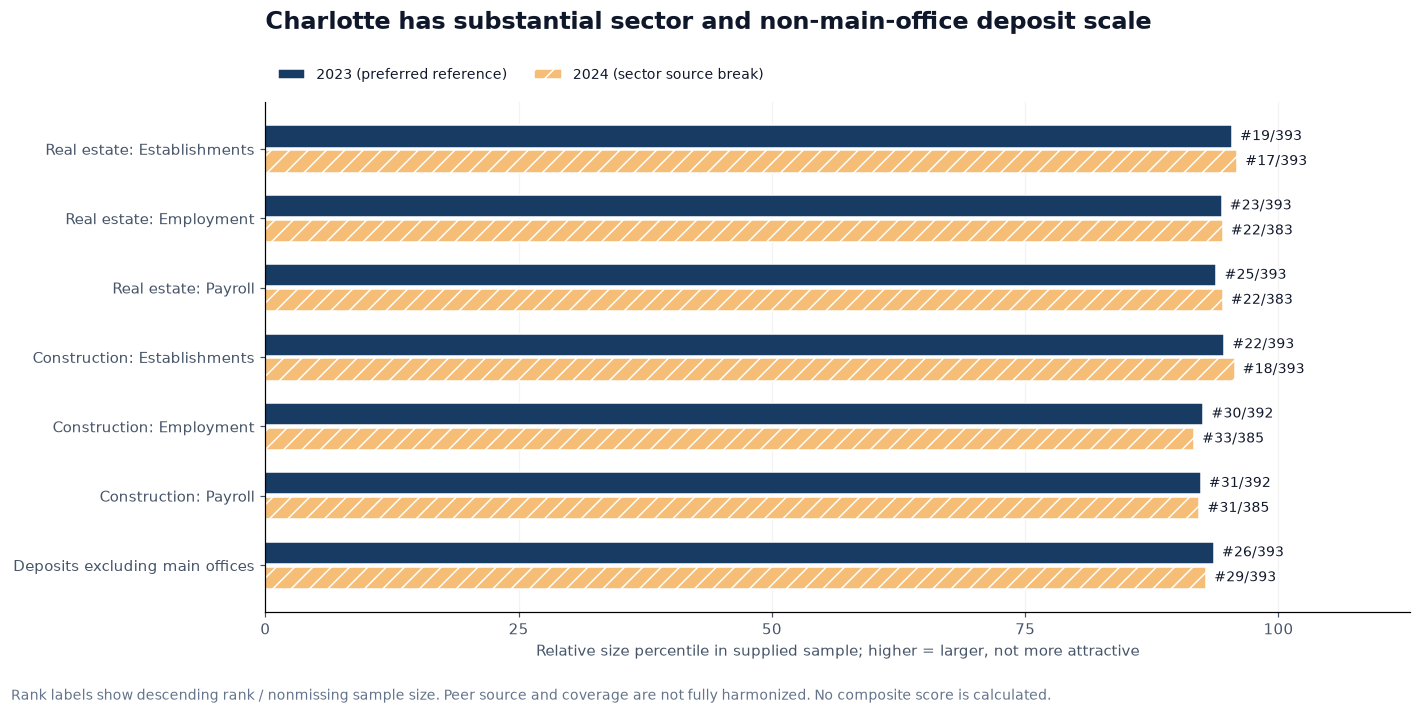

In [12]:
rank_rows = []
for year in [PREFERRED_END_YEAR, LATEST_YEAR]:
    peers = df[df['year'].eq(year)].set_index('cbsa_code')
    for col in ANALYSIS_COLS:
        valid = peers[col].dropna()
        valid = valid[valid.ge(0)]
        target = peers.loc[TARGET_CBSA, col]
        rank = valid.rank(method='min', ascending=False).get(TARGET_CBSA, np.nan)
        n = len(valid)
        rank_rows.append({
            'year': year, 'metric': col, 'label': LABELS[col], 'target_value': target,
            'rank_descending': rank, 'nonmissing_peer_count': n,
            'scale_percentile': 100 * (n - rank) / (n - 1) if n > 1 else np.nan,
            'peer_median': valid.median(),
            'target_over_peer_median': target / valid.median() if valid.median() > 0 else np.nan,
        })
rankings = pd.DataFrame(rank_rows)
display(rankings.drop(columns='metric'))
rankings.to_csv(OUTPUT_DIR / 'tables/charlotte_peer_rankings.csv', index=False)

plot_metrics = SECTOR_COLS + ['non_main_office_deposits_usd']
positions = np.arange(len(plot_metrics))
fig, ax = plt.subplots(figsize=(13, 6.2))
for shift, year, color, hatch in [(-.18, PREFERRED_END_YEAR, NAVY, ''), (.18, LATEST_YEAR, '#f5bd75', '//')]:
    r = rankings[rankings['year'].eq(year)].set_index('metric').loc[plot_metrics]
    ax.barh(positions + shift, r['scale_percentile'], height=.32, color=color, hatch=hatch,
            label=f'{year}' + (' (sector source break)' if year == LATEST_YEAR else ' (preferred reference)'), edgecolor='white')
    for y, (_, row) in zip(positions + shift, r.iterrows()):
        ax.text(row['scale_percentile'] + .8, y,
                f"#{row['rank_descending']:.0f}/{row['nonmissing_peer_count']:.0f}", va='center', fontsize=9)
ax.set_yticks(positions, [LABELS[c].replace('Nonresidential construction', 'Construction').replace(' (USD)', '') for c in plot_metrics])
ax.invert_yaxis()
ax.set_xlim(0, 113)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('Relative size percentile in supplied sample; higher = larger, not more attractive')
ax.set_title('Charlotte has substantial sector and non-main-office deposit scale', fontsize=16, loc='left', pad=48)
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.015), ncol=2, fontsize=9)
ax.grid(axis='x', alpha=.15)
ax.set_axisbelow(True)
fig.text(.01, -.035, 'Rank labels show descending rank / nonmissing sample size. Peer source and coverage are not fully harmonized. No composite score is calculated.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '07_peer_scale_rankings.png')

### Peer size versus employment growth

For this supplementary comparison, retain CBSAs with positive employment in every year
of the preferred window and stable, nonmissing source labels and reported/fallback count
fields. This is a stricter diagnostic filter, not proof of unchanged county identities or
industry definitions. No outliers are removed. Growth covers four annual intervals.

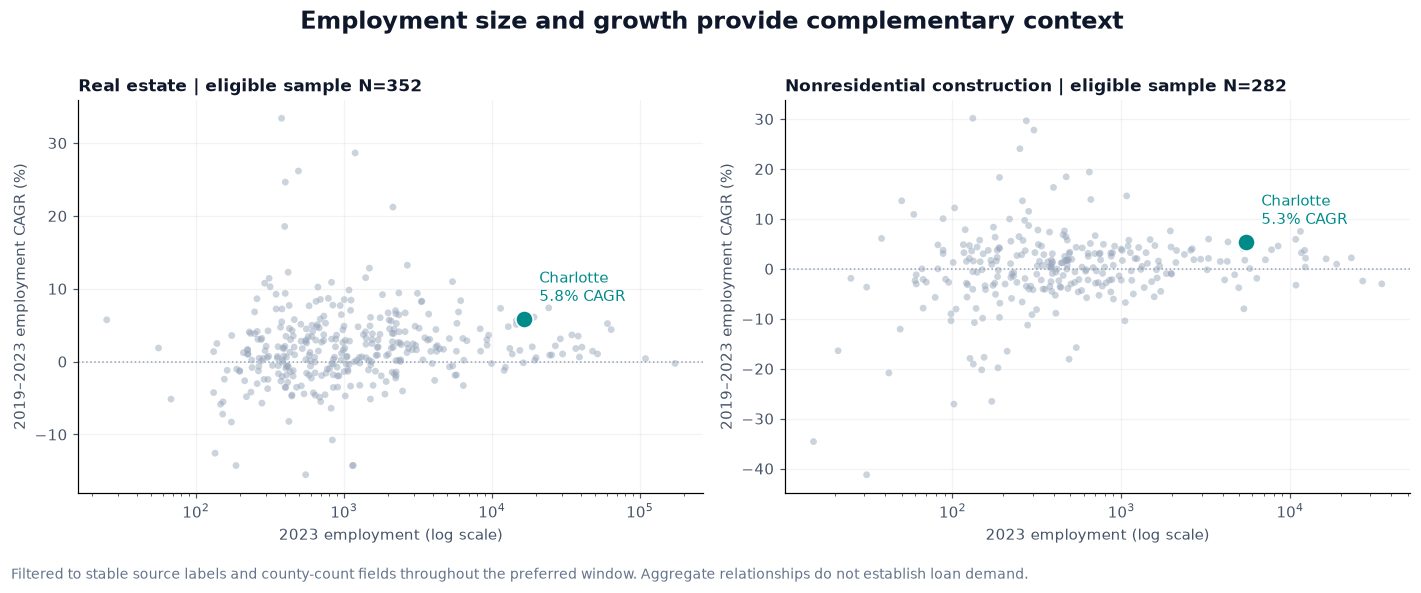

In [13]:
peer_growth_rows = []
window = df[df['year'].between(BASE_YEAR, PREFERRED_END_YEAR)]
for sector, label in SECTORS.items():
    checks = [f'{sector}_source', f'{sector}_counties_reported_count', f'{sector}_qcew_fallback_counties_count']
    col = f'{sector}_employment_count'
    for cbsa, g in window.groupby('cbsa_code'):
        if set(g['year']) != set(range(BASE_YEAR, PREFERRED_END_YEAR + 1)):
            continue
        if not g[checks + [col]].notna().all().all():
            continue
        if not g[checks].nunique().eq(1).all() or not g[col].gt(0).all():
            continue
        g = g.set_index('year')
        start, end = g.loc[BASE_YEAR, col], g.loc[PREFERRED_END_YEAR, col]
        peer_growth_rows.append({
            'cbsa_code': cbsa, 'cbsa_title': g.loc[PREFERRED_END_YEAR, 'cbsa_title'],
            'sector': sector, 'sector_label': label, 'end_employment': end,
            'employment_cagr_pct': 100 * ((end / start) ** (1 / (PREFERRED_END_YEAR - BASE_YEAR)) - 1),
        })
peer_growth = pd.DataFrame(peer_growth_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
for ax, (sector, label) in zip(axes, SECTORS.items()):
    q = peer_growth[peer_growth['sector'].eq(sector)]
    ax.scatter(q['end_employment'], q['employment_cagr_pct'], s=20, color=GREY, alpha=.48, edgecolor='none')
    target = q[q['cbsa_code'].eq(TARGET_CBSA)]
    if not target.empty:
        tx, ty = target.iloc[0][['end_employment', 'employment_cagr_pct']]
        ax.scatter([tx], [ty], color=TEAL, edgecolor='white', linewidth=1.2, s=130, zorder=4)
        ax.annotate(f'Charlotte\n{ty:.1f}% CAGR', (tx, ty), xytext=(10, 12), textcoords='offset points', color=TEAL, fontsize=10)
    ax.axhline(0, color=GREY, lw=1, linestyle=':')
    ax.set_xscale('log')
    ax.set_xlabel(f'{PREFERRED_END_YEAR} employment (log scale)')
    ax.set_ylabel(f'{BASE_YEAR}–{PREFERRED_END_YEAR} employment CAGR (%)')
    ax.set_title(f'{label} | eligible sample N={len(q)}', loc='left', fontsize=11)
    ax.grid(alpha=.14)
fig.suptitle('Employment size and growth provide complementary context', fontsize=16, fontweight='bold', y=1.02)
fig.text(.01, -.035, 'Filtered to stable source labels and county-count fields throughout the preferred window. Aggregate relationships do not establish loan demand.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '08_peer_employment_size_and_growth.png')
peer_growth.to_csv(OUTPUT_DIR / 'tables/filtered_peer_employment_growth.csv', index=False)

## 7. Assumptions, limits, and decision implications

The assumptions below are analytical choices, not verified pipeline guarantees.
The recommendations are inferences from the observed indicators; none estimates loan demand
or recommends a credit decision, a specific property type, or a branch location.

In [14]:
assumptions = pd.DataFrame([
    ('Market identity', 'CBSA 16740 and the supplied NC-SC title identify the target.', 'Validate county membership and boundary vintage against the DE crosswalk before location-level decisions.'),
    ('Industry mapping', 'Field labels stand in for real estate and nonresidential construction; exact NAICS is not supplied.', 'Do not equate all real estate businesses with CRE borrowers or infer office/industrial/multifamily exposure.'),
    ('Dollar units', 'Fields ending in _usd have already been normalized to USD.', 'Confirm CBP payroll and FDIC upstream unit conversion; do not multiply by 1,000 twice.'),
    ('Preferred window', '2019–2023 has stable Charlotte source labels and county-count fields.', 'Construction remains CBP+QCEW; stable labels and totals do not prove identical county or firm coverage.'),
    ('Latest observation', '2024 CRE observations are retained, with a source-break flag.', 'Do not score 2024 raw CRE growth as fully comparable; obtain a common-source history.'),
    ('Nominal values', 'Payroll and deposits are not inflation-adjusted.', 'Dollar growth is not real economic growth or improved borrower profitability.'),
    ('Deposits', 'Subtract main-office balances exactly as supplied.', 'Result is not commercial-only, local-origin, insured-only, or immediately contestable deposits.'),
    ('Timing', 'SOD is June 30; CBP employment is March-based; QCEW annual employment averages monthly values.', 'The annual record combines different reference periods; no causal contemporaneous model is fitted.'),
    ('Coverage fields', 'Use reported and fallback counts separately; 11 is a file-derived diagnostic reference.', 'A zero reported count can coexist with fallback observations; verify field semantics and non-overlap.'),
    ('Establishments', 'Counts measure locations, not consolidated firms.', 'No conversion from establishments to borrowers, loans above $1M, or average ticket size.'),
    ('Missing data', 'No imputation; derived ratios require positive denominators.', 'Peer sample sizes differ and ranks reflect the available sample only.'),
    ('Peer comparison', 'Use the CBSAs present in the supplied file.', 'Not a verified current national universe or matched banking peer set; larger is not necessarily more attractive.'),
    ('Data currency', 'Historical input ends in 2024, analyzed in October 2026.', 'Refresh and reconcile vintages before committing capital or assigning current market scores.'),
], columns=['Topic', 'Assumption / treatment', 'Implication / required validation'])
display(assumptions)
assumptions.to_csv(OUTPUT_DIR / 'tables/assumptions.csv', index=False)

recommendations = pd.DataFrame([
    ('1 — Measurement gate', 'Rebuild sector time series on one source and confirm industry/geographic definitions.',
     'Both 2024 sector source labels change to QCEW; prior construction coverage also varies.',
     'DE + ML', 'Common-source 2019–latest series, NAICS list, county crosswalk, ownership scope, unit tests, and documented suppression rules.'),
    ('2 — Prospect qualification', 'Use sector growth to build a relationship prospect list, then qualify firms for the >$1M strategy.',
     'Employment and establishment expansion show business activity; firm revenue and borrowing needs are absent.',
     'Commercial/RM team', 'Firm-level revenue, size, parent ownership, existing facilities, financing needs, and sponsor eligibility criteria.'),
    ('3 — Deposit investigation', 'Reconcile the declining non-main-office balances by bank and branch before interpreting competitive opportunity.',
     'Headline growth is driven by main-office balances while the remaining balance declines.',
     'Banking analytics + treasury', 'Institution/branch-level SOD bridge with mergers, booking transfers, branch changes, and main-office flags.'),
    ('4 — Treasury discovery', 'Investigate payroll, operating accounts, payables/receivables and cash-management needs alongside lending.',
     'Sector payroll flows expanded; aggregate payroll does not reveal account ownership or deposit retention.',
     'Treasury + RM team', 'Customer transaction needs, account relationships, liquidity patterns, and pricing economics.'),
    ('5 — CRE underwriting context', 'Add property- and project-level fundamentals before selecting asset classes or construction exposure.',
     'Business activity does not measure vacancy, absorption, rents, project pipeline, collateral value, or debt service.',
     'CRE + risk team', 'Property type, location, occupancy, absorption, pipeline, NOI, DSCR, leverage, sponsor strength, and maturity/refinancing needs.'),
    ('6 — Deployment decision', 'Use this EDA as a screening input; combine it with the other pillars and current internal evidence.',
     'MSA aggregates cannot identify the next neighborhood, branch format, RM location, or marginal return.',
     'Strategy + ML pod', 'Current pipeline, loan/deposit balances, RM coverage, customer geography, competition, risk limits, and refreshed data.'),
], columns=['Priority', 'Recommendation', 'Evidence / reason', 'Suggested owner', 'Concrete next deliverable'])
display(recommendations)
recommendations.to_csv(OUTPUT_DIR / 'tables/recommendations.csv', index=False)

,Topic,Assumption / treatment,Implication / required validation
0,Market identity,CBSA 16740 and the supplied NC-SC title identi...,Validate county membership and boundary vintag...
1,Industry mapping,Field labels stand in for real estate and nonr...,Do not equate all real estate businesses with ...
2,Dollar units,Fields ending in _usd have already been normal...,Confirm CBP payroll and FDIC upstream unit con...
3,Preferred window,2019–2023 has stable Charlotte source labels a...,Construction remains CBP+QCEW; stable labels a...
4,Latest observation,"2024 CRE observations are retained, with a sou...",Do not score 2024 raw CRE growth as fully comp...
5,Nominal values,Payroll and deposits are not inflation-adjusted.,Dollar growth is not real economic growth or i...
6,Deposits,Subtract main-office balances exactly as suppl...,"Result is not commercial-only, local-origin, i..."
7,Timing,SOD is June 30; CBP employment is March-based;...,The annual record combines different reference...
8,Coverage fields,Use reported and fallback counts separately; 1...,A zero reported count can coexist with fallbac...
9,Establishments,"Counts measure locations, not consolidated firms.",No conversion from establishments to borrowers...


,Priority,Recommendation,Evidence / reason,Suggested owner,Concrete next deliverable
0,1 — Measurement gate,Rebuild sector time series on one source and c...,Both 2024 sector source labels change to QCEW;...,DE + ML,"Common-source 2019–latest series, NAICS list, ..."
1,2 — Prospect qualification,Use sector growth to build a relationship pros...,Employment and establishment expansion show bu...,Commercial/RM team,"Firm-level revenue, size, parent ownership, ex..."
2,3 — Deposit investigation,Reconcile the declining non-main-office balanc...,Headline growth is driven by main-office balan...,Banking analytics + treasury,Institution/branch-level SOD bridge with merge...
3,4 — Treasury discovery,"Investigate payroll, operating accounts, payab...",Sector payroll flows expanded; aggregate payro...,Treasury + RM team,"Customer transaction needs, account relationsh..."
4,5 — CRE underwriting context,Add property- and project-level fundamentals b...,"Business activity does not measure vacancy, ab...",CRE + risk team,"Property type, location, occupancy, absorption..."
5,6 — Deployment decision,Use this EDA as a screening input; combine it ...,MSA aggregates cannot identify the next neighb...,Strategy + ML pod,"Current pipeline, loan/deposit balances, RM co..."


 # 8. Executive interpretation
 The following summary is generated from the calculations above. Recommendations are
investigation priorities under the supplied historical evidence, not a lending forecast.

### Findings from the supplied file

- **Growing sector activity:** Real estate establishments increased {total_growth('cre_real_estate_establishments_count'):.1f}% and employment increased {total_growth('cre_real_estate_employment_count'):.1f}% during {BASE_YEAR}–{PREFERRED_END_YEAR}. Nonresidential construction employment increased {total_growth('cre_nonres_construction_employment_count'):.1f}%.
- **Relationship scale, not loan volume:** {PREFERRED_END_YEAR} real estate and construction establishments averaged {charlotte.loc[PREFERRED_END_YEAR, 'cre_real_estate_employees_per_establishment']:.1f} and {charlotte.loc[PREFERRED_END_YEAR, 'cre_nonres_construction_employees_per_establishment']:.1f} employees respectively. Neither identifies consolidated corporate borrowers.
- **Deposit divergence:** {LATEST_YEAR} total deposits grew {latest_total_yoy:.1f}%, but deposits excluding main offices fell {abs(latest_nonmain_yoy):.1f}% to ${latest_nonmain:.2f}B. Main offices accounted for {charlotte.loc[LATEST_YEAR, 'main_office_share_pct']:.1f}% of total balances. The aggregate file does not identify the cause.
- **Measurement gate:** Both CRE sectors switch to QCEW in {LATEST_YEAR}. Observed growth crossing that break needs common-source validation.

### Recommendation

Continue targeted commercial relationship investigation, with real estate- and contractor-related
prospects as candidate segments. Validate source consistency, qualify firms for the greater-than-$1M
strategy, investigate deposit movements by institution, and add property-level risk evidence before
deciding capital, credit exposure, RM placement, or physical presence.

### Assumptions and limitations

All dollars are nominal; units and sector mappings are accepted from the supplied pipeline labels.
Coverage counts and source labels are diagnostic, not proof of harmonization. Deposits excluding main
offices are not commercial-only deposits. Establishments are not unique borrowers. No loan-dollar
estimate, causal inference, composite score, or location recommendation is produced. The snapshot
ends in 2024 and requires refreshing for a current decision.

### Official methodological references

- Census County Business Patterns: https://www.census.gov/programs-surveys/cbp.html
- Census CBP glossary: https://www.census.gov/programs-surveys/cbp/about/glossary.html
- BLS QCEW annual definitions: https://www.bls.gov/cew/publications/employment-and-wages-annual-averages/2025/home.htm
- FDIC Summary of Deposits: https://www.fdic.gov/bank-financial-reports/summary-deposits

External references explain statistical concepts only; all market figures in this analysis
come from the supplied parquet. The upstream NAICS/county/ownership contracts were not supplied.

# 9.  Industry activity and the potential commercial borrower base

**New input:** `msa_naics_year.parquet`, at **CBSA × two-digit NAICS sector × year**.
This section broadens the analysis beyond the narrower CRE measures in Sections 1–8.

**Why it helps:** sector establishments describe the prospect-location base; employment
and employees per location describe operating scale; establishment and job growth describe
expansion; payroll describes labor-payment activity. These indicators can guide company
identification and financing conversations. They are **not observed loan demand** and
cannot identify the number of eligible borrowers or dollars of loans above $1 million.

**Commercial versus corporate:** for commercial prospecting, use industry scale and growth
to decide which companies to investigate. For corporate lending, local employment is only
context: obtain consolidated company revenue, ownership, existing debt, borrowing authority,
and financing plans. A local branch may belong to a much larger enterprise.

NAICS 31 represents manufacturing 31–33; 44 represents retail 44–45; 48 represents
transportation and warehousing 48–49. Code 99 is unclassified. Broad sector 23 includes
all construction and broad sector 53 includes real estate plus rental and leasing; neither
is a substitute for the narrower original CRE fields.

Sources: [Census CBP glossary](https://www.census.gov/programs-surveys/cbp/about/glossary.html),
[CBP methodology](https://www.census.gov/programs-surveys/cbp/technical-documentation/methodology.html),
[Census SUSB enterprise-size data](https://www.census.gov/programs-surveys/susb.html).
All new market figures below come from the supplied NAICS file, not external estimates.

In [30]:
# NAICS_DATA_PATH = None #  # To use embedded original snapshot.
NAICS_DATA_PATH = "../data/processed/msa_naics_year.parquet"        
NAICS_BASE_YEAR = BASE_YEAR
NAICS_END_YEAR = 2023
NAICS_ORIGINAL_SHA256 = '210dd8dec2df91c8778ff78b50619cf767661cdb1347163e15b02c6e4d300e3d'
NAICS_EMBEDDED_ZLIB_BASE64 = '...'
if NAICS_DATA_PATH is None:
    naics_bytes = zlib.decompress(base64.b64decode(NAICS_EMBEDDED_ZLIB_BASE64))
    assert hashlib.sha256(naics_bytes).hexdigest() == NAICS_ORIGINAL_SHA256
    naics_origin = 'Embedded original msa_naics_year.parquet'
else:
    naics_bytes = Path(NAICS_DATA_PATH).expanduser().read_bytes()
    naics_origin = str(Path(NAICS_DATA_PATH).expanduser().resolve())
naics_raw = pd.read_parquet(BytesIO(naics_bytes))
naics_provenance = {'input': naics_origin, 'sha256': hashlib.sha256(naics_bytes).hexdigest(),
                    'bytes': len(naics_bytes), 'rows': len(naics_raw)}
display(pd.DataFrame([naics_provenance]))



,input,sha256,bytes,rows
0,C:\Users\evand\Desktop\bankunited-market-expan...,210dd8dec2df91c8778ff78b50619cf767661cdb134716...,678047,67487


In [31]:
N_KEYS = ['cbsa_code', 'naics_code', 'year']
N_VALUES = ['cbp_establishments_count', 'cbp_employment_count', 'cbp_annual_payroll_usd']
N_REQUIRED = N_KEYS + N_VALUES + ['cbp_counties_reported_count']
if set(N_REQUIRED) - set(naics_raw.columns):
    raise ValueError(f'Missing NAICS columns: {sorted(set(N_REQUIRED) - set(naics_raw.columns))}')
naics = naics_raw[N_REQUIRED].copy()
naics['cbsa_code'] = naics['cbsa_code'].astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(5)
naics['naics_code'] = naics['naics_code'].astype('string').str.zfill(2)
for c in ['year'] + N_VALUES + ['cbp_counties_reported_count']:
    naics[c] = pd.to_numeric(naics[c], errors='raise')
naics['year'] = naics['year'].astype(int)
if naics[N_KEYS].isna().any().any() or naics.duplicated(N_KEYS).any():
    raise ValueError('NAICS keys must be nonmissing and unique at CBSA × sector × year.')
if (naics[N_VALUES + ['cbp_counties_reported_count']] < 0).any().any():
    raise ValueError('Negative NAICS values require upstream review.')

NAICS_LABELS = {
    '11': 'Agriculture forestry fishing and hunting', '21': 'Mining quarrying and oil and gas',
    '22': 'Utilities', '23': 'Construction', '31': 'Manufacturing', '42': 'Wholesale trade',
    '44': 'Retail trade', '48': 'Transportation and warehousing', '51': 'Information',
    '52': 'Finance and insurance', '53': 'Real estate and rental and leasing',
    '54': 'Professional scientific and technical services', '55': 'Management of companies and enterprises',
    '56': 'Administrative support and waste services', '61': 'Educational services',
    '62': 'Health care and social assistance', '71': 'Arts entertainment and recreation',
    '72': 'Accommodation and food services', '81': 'Other services except public administration',
    '99': 'Unclassified',
}
unknown = set(naics['naics_code']) - set(NAICS_LABELS)
if unknown:
    raise ValueError(f'Update the sector mapping for these codes: {sorted(unknown)}')
naics['sector_name'] = naics['naics_code'].map(NAICS_LABELS)
naics = naics.sort_values(N_KEYS).reset_index(drop=True)
nc = naics[naics['cbsa_code'].eq(TARGET_CBSA)].copy()
if nc.empty or NAICS_END_YEAR not in nc['year'].values:
    raise ValueError('Target CBSA or the requested NAICS end year is absent.')
if NAICS_BASE_YEAR >= NAICS_END_YEAR:
    raise ValueError('The NAICS comparison window requires an end year after the base year.')
naics_audit = pd.DataFrame([
    ('Input rows', len(naics)), ('Distinct CBSAs', naics['cbsa_code'].nunique()),
    ('Distinct sector groups including unclassified', naics['naics_code'].nunique()),
    ('First year', naics['year'].min()), ('Last year', naics['year'].max()),
    ('Duplicate keys', int(naics.duplicated(N_KEYS).sum())),
    ('Target rows', len(nc)), ('Target missing numeric cells', int(nc[N_VALUES].isna().sum().sum())),
    ('Input missing employment cells', int(naics['cbp_employment_count'].isna().sum())),
    ('Input missing payroll cells', int(naics['cbp_annual_payroll_usd'].isna().sum())),
], columns=['Check', 'Result'])
display(naics_audit)
naics_audit.to_csv(OUTPUT_DIR / 'tables/naics_data_audit.csv', index=False)
nc.to_csv(OUTPUT_DIR / 'tables/charlotte_naics_annual_input.csv', index=False)

# The grain differs from the original market file. Aggregate sectors BEFORE
# comparing to a CBSA-year total; do not repeat and sum deposits once per sector.
sector_sums = nc.groupby('year')[N_VALUES].sum(min_count=1)
original_market_cbp = raw_df[raw_df['cbsa_code'].astype(str).eq(TARGET_CBSA)].set_index('year')[N_VALUES]
reconciliation = sector_sums.add_suffix('_sector_sum').join(
    original_market_cbp.add_suffix('_market_total'), how='left')
for c in N_VALUES:
    reconciliation[c + '_gap_market_minus_sectors'] = reconciliation[c + '_market_total'] - reconciliation[c + '_sector_sum']
    reconciliation[c + '_observed_pct_of_market_total'] = 100 * safe_divide(
        reconciliation[c + '_sector_sum'], reconciliation[c + '_market_total'])
display(Markdown('**Reconciliation with the original market file (includes code 99 in sector sums):**'))
display(reconciliation)
reconciliation.to_csv(OUTPUT_DIR / 'tables/naics_to_market_reconciliation.csv')

,Check,Result
0,Input rows,67487
1,Distinct CBSAs,387
2,Distinct sector groups including unclassified,20
3,First year,2015
4,Last year,2023
5,Duplicate keys,0
6,Target rows,180
7,Target missing numeric cells,0
8,Input missing employment cells,727
9,Input missing payroll cells,727


**Reconciliation with the original market file (includes code 99 in sector sums):**

,cbp_establishments_count_sector_sum,cbp_employment_count_sector_sum,cbp_annual_payroll_usd_sector_sum,cbp_establishments_count_market_total,cbp_employment_count_market_total,cbp_annual_payroll_usd_market_total,cbp_establishments_count_gap_market_minus_sectors,cbp_establishments_count_observed_pct_of_market_total,cbp_employment_count_gap_market_minus_sectors,cbp_employment_count_observed_pct_of_market_total,cbp_annual_payroll_usd_gap_market_minus_sectors,cbp_annual_payroll_usd_observed_pct_of_market_total
year,,,,,,,,,,,,
2015,58042,"982,062.00","50,611,206,000.00","58,042.00","993,276.00","51,833,530,000.00",0.00,100.00,"11,214.00",98.87,"1,222,324,000.00",97.64
2016,59799,"1,024,704.00","53,297,278,000.00","59,799.00","1,028,588.00","53,748,402,000.00",0.00,100.00,"3,884.00",99.62,"451,124,000.00",99.16
2017,62023,"1,045,848.00","55,049,617,000.00","62,039.00","1,058,398.00","56,375,231,000.00",16.00,99.97,"12,550.00",98.81,"1,325,614,000.00",97.65
2018,62807,"1,083,801.00","59,415,870,000.00","62,819.00","1,083,925.00","59,423,192,000.00",12.00,99.98,124.00,99.99,"7,322,000.00",99.99
2019,64251,"1,118,030.00","63,227,449,000.00","64,262.00","1,118,149.00","63,234,364,000.00",11.00,99.98,119.00,99.99,"6,915,000.00",99.99
2020,65498,"1,138,019.00","64,985,481,000.00","65,509.00","1,138,126.00","64,992,242,000.00",11.00,99.98,107.00,99.99,"6,761,000.00",99.99
2021,68046,"1,112,507.00","71,039,615,000.00","68,054.00","1,112,606.00","71,047,010,000.00",8.00,99.99,99.00,99.99,"7,395,000.00",99.99
2022,70331,"1,177,656.00","78,229,652,000.00","70,346.00","1,178,479.00","78,302,894,000.00",15.00,99.98,823.00,99.93,"73,242,000.00",99.91
2023,71394,"1,237,980.00","84,930,272,000.00","71,411.00","1,238,884.00","85,013,927,000.00",17.00,99.98,904.00,99.93,"83,655,000.00",99.90


## 9A Coverage and interpretation rules

The NAICS file ends in **2023**; do not attach the original 2024 CRE growth rates to these
sectors. The original input covers 393 CBSAs and this file covers 387, so do not assume an
identical peer universe.

`cbp_counties_reported_count` is a joint publication diagnostic for establishments,
employment and payroll. It cannot independently establish the coverage of each measure.
Charlotte's reference of 11 counties comes from the existing project data. A lower count
may reflect absent sector rows, confidentiality rules or incomplete collection; it does not
by itself prove an economic contraction or quantify an undercount. Stable counts do not
guarantee stable county identities. Earlier suppression rules and the change to noise infusion
also limit historical comparisons. No missing value is converted to zero.

The sector totals do not exactly reconcile to the original all-industry CBP totals.
Keep and disclose the residual rather than forcing a match. Industry shares below use the
**observed classified-sector sum**, excluding code 99; they are not shares of the entire
Charlotte economy. They are descriptive and not used as a credit score.

In [19]:
coverage_n = nc.pivot(index='naics_code', columns='year', values='cbp_counties_reported_count').sort_index()
records = []
for sector, group in nc.groupby('naics_code'):
    group = group.set_index('year').sort_index()
    if not {NAICS_BASE_YEAR, NAICS_END_YEAR}.issubset(group.index):
        continue
    window = group.loc[NAICS_BASE_YEAR:NAICS_END_YEAR]
    expected_years = set(range(NAICS_BASE_YEAR, NAICS_END_YEAR + 1))
    complete_window = set(window.index) == expected_years and window[N_VALUES].notna().all().all()
    full_count_window = complete_window and window['cbp_counties_reported_count'].eq(REFERENCE_COUNTIES).all()
    r = {'naics_code': sector, 'sector_name': NAICS_LABELS[sector],
         'reported_counties_latest': group.loc[NAICS_END_YEAR, 'cbp_counties_reported_count'],
         'reported_count_stable_in_window': bool(window['cbp_counties_reported_count'].nunique() == 1),
         'all_years_and_measures_present': bool(complete_window),
         'reference_count_all_years': bool(full_count_window)}
    for c in N_VALUES:
        start, end = group.loc[NAICS_BASE_YEAR, c], group.loc[NAICS_END_YEAR, c]
        r[c + '_base'] = start
        r[c + '_latest'] = end
        r[c + '_growth_pct'] = 100 * (end / start - 1) if pd.notna(start) and start > 0 else np.nan
        r[c + '_cagr_pct'] = 100 * ((end / start)**(1 / (NAICS_END_YEAR - NAICS_BASE_YEAR)) - 1) if pd.notna(start) and pd.notna(end) and start > 0 and end > 0 else np.nan
    est, emp, pay = [r[c + '_latest'] for c in N_VALUES]
    r['employees_per_location'] = emp / est if est > 0 else np.nan
    r['payroll_per_location_usd'] = pay / est if est > 0 else np.nan
    records.append(r)
ns = pd.DataFrame(records).set_index('naics_code').sort_index()
classified = ns.index != '99'
for c in N_VALUES:
    denom = ns.loc[classified, c + '_latest'].sum(min_count=1)
    ns[c + '_observed_classified_share_pct'] = np.nan
    if denom > 0:
        ns.loc[classified, c + '_observed_classified_share_pct'] = 100 * ns.loc[classified, c + '_latest'] / denom

display(Markdown(f'**All sectors: observed {NAICS_END_YEAR} scale and {NAICS_BASE_YEAR}–{NAICS_END_YEAR} growth**'))
display(ns[['sector_name', 'cbp_establishments_count_latest', 'cbp_employment_count_latest',
            'cbp_annual_payroll_usd_latest', 'cbp_establishments_count_growth_pct',
            'cbp_employment_count_growth_pct', 'cbp_annual_payroll_usd_growth_pct',
            'employees_per_location', 'reported_counties_latest', 'reference_count_all_years']])
ns.to_csv(OUTPUT_DIR / 'tables/charlotte_naics_sector_summary.csv')
coverage_n.to_csv(OUTPUT_DIR / 'tables/charlotte_naics_county_coverage.csv')

**All sectors: observed 2023 scale and 2019–2023 growth**

,sector_name,cbp_establishments_count_latest,cbp_employment_count_latest,cbp_annual_payroll_usd_latest,cbp_establishments_count_growth_pct,cbp_employment_count_growth_pct,cbp_annual_payroll_usd_growth_pct,employees_per_location,reported_counties_latest,reference_count_all_years
naics_code,,,,,,,,,,
11,Agriculture forestry fishing and hunting,116,726.00,"41,984,000.00",6.42,13.97,43.17,6.26,11,False
21,Mining quarrying and oil and gas,28,372.00,"29,411,000.00",0.00,-58.25,-52.88,13.29,4,False
22,Utilities,162,"10,393.00","1,244,921,000.00",-4.14,0.44,5.53,64.15,10,False
23,Construction,7500,"73,922.00","5,472,691,000.00",18.02,17.69,46.51,9.86,11,True
31,Manufacturing,2341,"110,240.00","6,979,073,000.00",1.34,5.80,24.85,47.09,11,True
42,Wholesale trade,3683,"65,207.00","5,232,911,000.00",-3.76,7.39,26.79,17.70,11,True
44,Retail trade,8197,"145,851.00","5,240,057,000.00",3.97,14.41,49.06,17.79,11,True
48,Transportation and warehousing,2680,"77,790.00","4,762,428,000.00",26.59,35.70,55.91,29.03,11,True
51,Information,1150,"29,354.00","3,108,040,000.00",2.68,-4.43,21.35,25.53,11,True


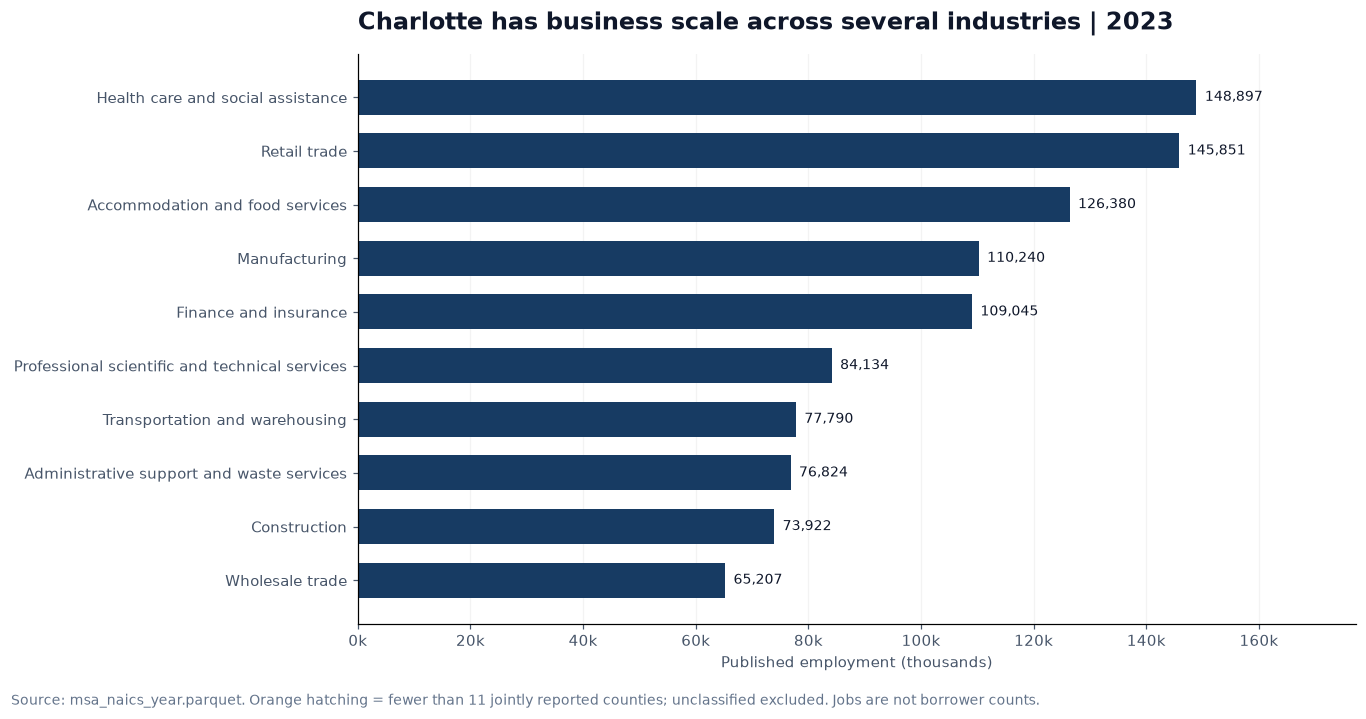

In [20]:
top = ns.loc[classified].nlargest(10, 'cbp_employment_count_latest').sort_values('cbp_employment_count_latest')
fig, ax = plt.subplots(figsize=(12.5, 6.3))
values = top['cbp_employment_count_latest']
colors = [NAVY if x == REFERENCE_COUNTIES else ORANGE for x in top['reported_counties_latest']]
bars = ax.barh(top['sector_name'], values, color=colors, height=.65)
for bar, (sector, row) in zip(bars, top.iterrows()):
    if row['reported_counties_latest'] != REFERENCE_COUNTIES:
        bar.set_hatch('//')
    ax.text(row['cbp_employment_count_latest'] + 1500, bar.get_y() + bar.get_height()/2,
            f"{row['cbp_employment_count_latest']:,.0f}", va='center', fontsize=9)
ax.set_xlim(0, values.max()*1.19)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:.0f}k'))
ax.set_xlabel('Published employment (thousands)')
ax.set_title(f'Charlotte has business scale across several industries | {NAICS_END_YEAR}', loc='left', fontsize=16, pad=16)
ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
fig.text(.01, -.025, 'Source: msa_naics_year.parquet. Orange hatching = fewer than 11 jointly reported counties; unclassified excluded. Jobs are not borrower counts.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '09_naics_employment_scale.png')

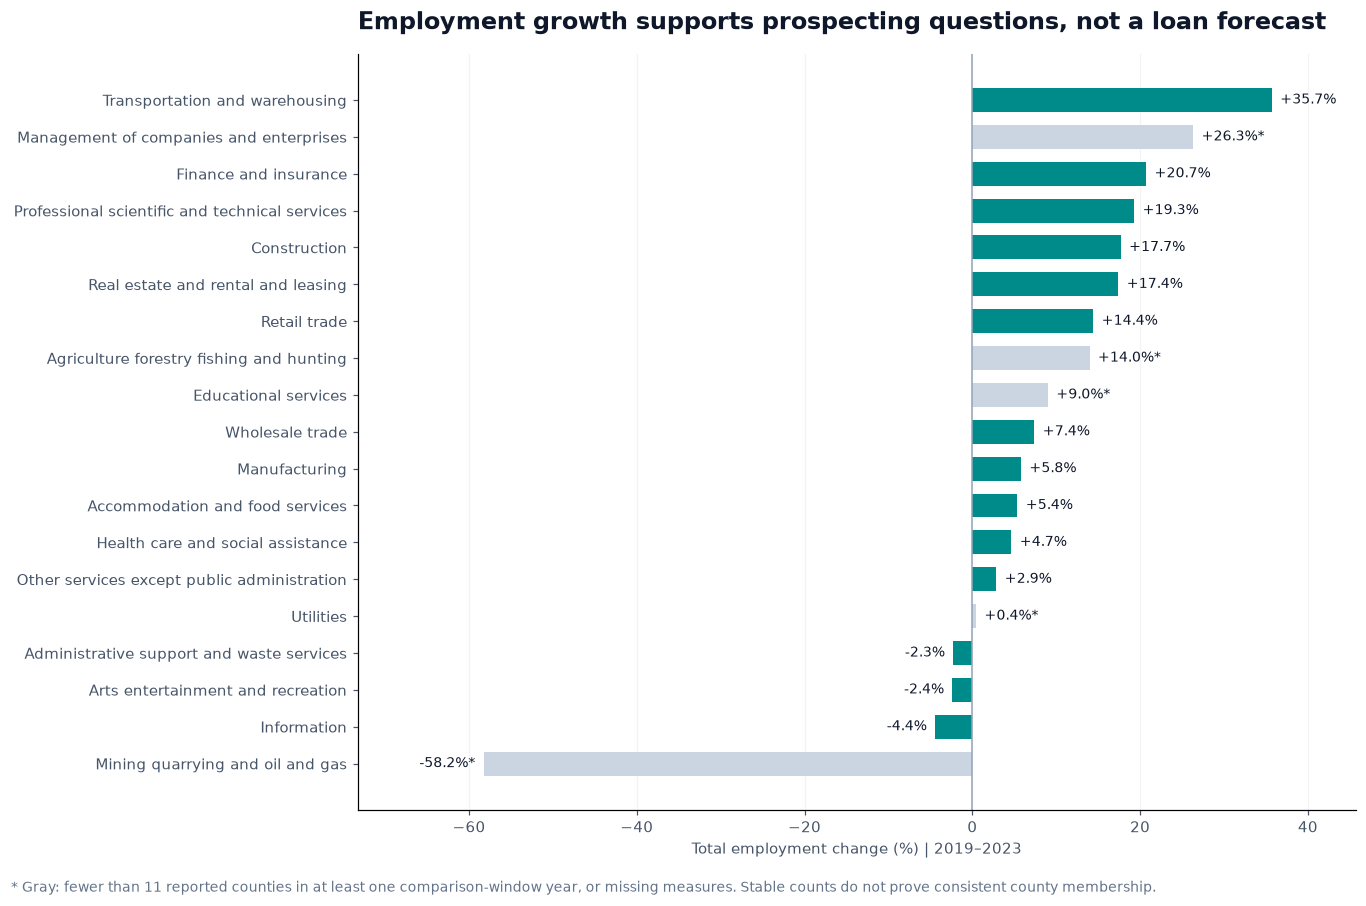

In [21]:
q = ns.loc[classified].sort_values('cbp_employment_count_growth_pct')
fig, ax = plt.subplots(figsize=(12.5, 8))
vals = q['cbp_employment_count_growth_pct']
colors = [TEAL if x else '#cbd5e1' for x in q['reference_count_all_years']]
bars = ax.barh(q['sector_name'], vals, color=colors, height=.65)
for bar, (_, r) in zip(bars, q.iterrows()):
    v = r['cbp_employment_count_growth_pct']
    ax.text(v + (1 if v >= 0 else -1), bar.get_y()+bar.get_height()/2,
            f'{v:+.1f}%' + ('*' if not r['reference_count_all_years'] else ''),
            ha='left' if v >= 0 else 'right', va='center', fontsize=9)
ax.set_xlim(min(-5, vals.min()-15), max(45, vals.max()+10))
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel(f'Total employment change (%) | {NAICS_BASE_YEAR}–{NAICS_END_YEAR}')
ax.set_title('Employment growth supports prospecting questions, not a loan forecast', loc='left', fontsize=16, pad=16)
ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
fig.text(.01, -.02, '* Gray: fewer than 11 reported counties in at least one comparison-window year, or missing measures. Stable counts do not prove consistent county membership.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '10_naics_employment_growth.png')

## 9B Candidate industries for commercial relationship investigation

The five industries below are **examples to investigate**, chosen to illustrate equipment,
working-capital and business-service relationships across different sectors. They are not an
optimized ranking or an assertion of BankUnited's preferred industries. Each has the 11-county
reference count in every year of the comparison window. Risk appetite and company-level
financing needs still determine fit.

Employees per location is an operating-scale proxy, not company size. A sector with many
employees per location may contain large operations, but a local establishment can be a branch
of an enterprise whose financing decisions are made elsewhere. Payroll is nominal and can
increase through wage changes without additional borrowing. Do not multiply payroll, jobs,
or establishments by an assumed loan size.

,sector_name,cbp_establishments_count_latest,cbp_employment_count_latest,cbp_establishments_count_growth_pct,cbp_employment_count_growth_pct,employees_per_location,financing_need_to_test
naics_code,,,,,,,
48,Transportation and warehousing,2680,"77,790.00",26.59,35.70,29.03,Fleet or equipment finance; receivables and wo...
31,Manufacturing,2341,"110,240.00",1.34,5.80,47.09,Machinery investment; inventory and working ca...
42,Wholesale trade,3683,"65,207.00",-3.76,7.39,17.70,Inventory or receivables finance; working capital
54,Professional scientific and technical services,8569,"84,134.00",17.98,19.30,9.82,Working capital; acquisitions; operating accou...
62,Health care and social assistance,7235,"148,897.00",16.45,4.66,20.58,Facilities or equipment finance; receivables a...


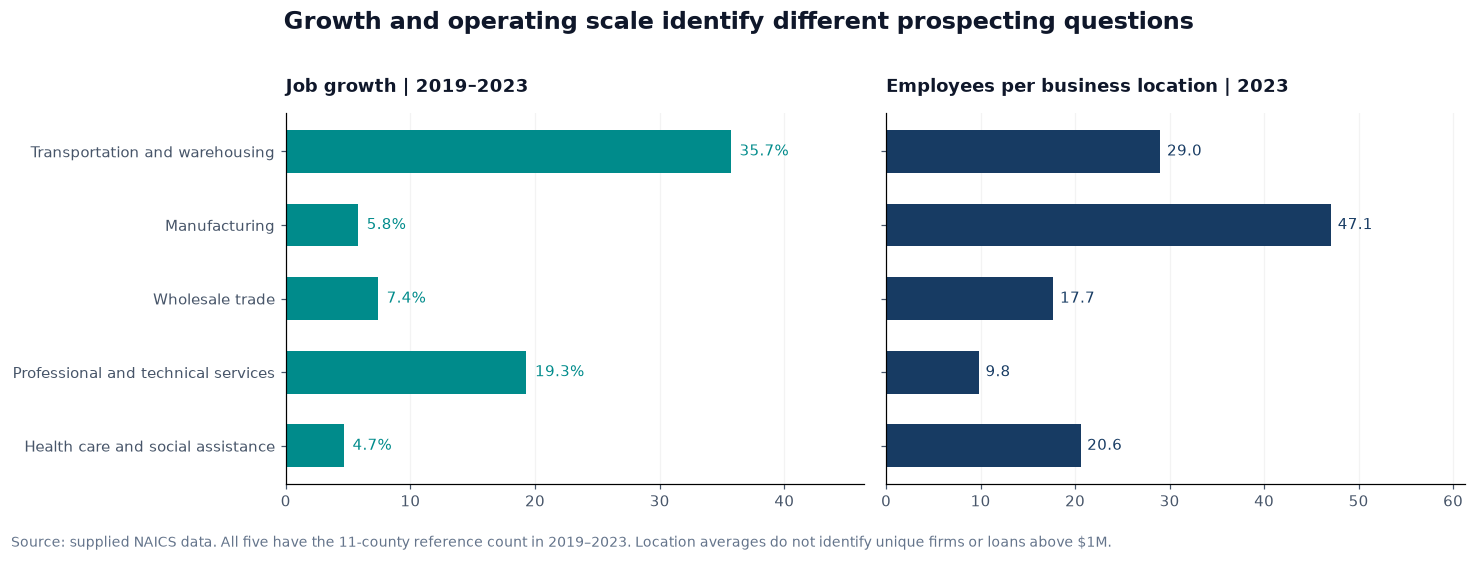

In [22]:
FOCUS_NAICS = ['48', '31', '42', '54', '62']
focus = ns.loc[FOCUS_NAICS].copy()
focus['financing_need_to_test'] = [
    'Fleet or equipment finance; receivables and working capital',
    'Machinery investment; inventory and working capital',
    'Inventory or receivables finance; working capital',
    'Working capital; acquisitions; operating accounts and payments',
    'Facilities or equipment finance; receivables and working capital',
]
display(focus[['sector_name', 'cbp_establishments_count_latest', 'cbp_employment_count_latest',
               'cbp_establishments_count_growth_pct', 'cbp_employment_count_growth_pct',
               'employees_per_location', 'financing_need_to_test']])
focus.to_csv(OUTPUT_DIR / 'tables/charlotte_naics_commercial_candidates.csv')
short = ['Transportation and warehousing', 'Manufacturing', 'Wholesale trade',
         'Professional and technical services', 'Health care and social assistance']
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
for ax, col, title, suffix, color in [
    (axes[0], 'cbp_employment_count_growth_pct', f'Job growth | {NAICS_BASE_YEAR}–{NAICS_END_YEAR}', '%', TEAL),
    (axes[1], 'employees_per_location', f'Employees per business location | {NAICS_END_YEAR}', '', NAVY),
]:
    y = np.arange(len(focus))
    bars = ax.barh(y, focus[col], color=color, height=.58)
    ax.set_yticks(y, short if ax is axes[0] else ['']*len(short))
    ax.invert_yaxis()
    for bar, val in zip(bars, focus[col]):
        ax.text(val + .7, bar.get_y()+bar.get_height()/2, f'{val:.1f}{suffix}', va='center', fontsize=10, color=color)
    ax.set_xlim(0, focus[col].max()*1.3)
    ax.set_title(title, loc='left', fontsize=12, pad=14)
    ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
fig.suptitle('Growth and operating scale identify different prospecting questions', fontsize=16, fontweight='bold', y=1.02)
fig.text(.01, -.04, 'Source: supplied NAICS data. All five have the 11-county reference count in 2019–2023. Location averages do not identify unique firms or loans above $1M.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '11_naics_commercial_growth_and_scale.png')

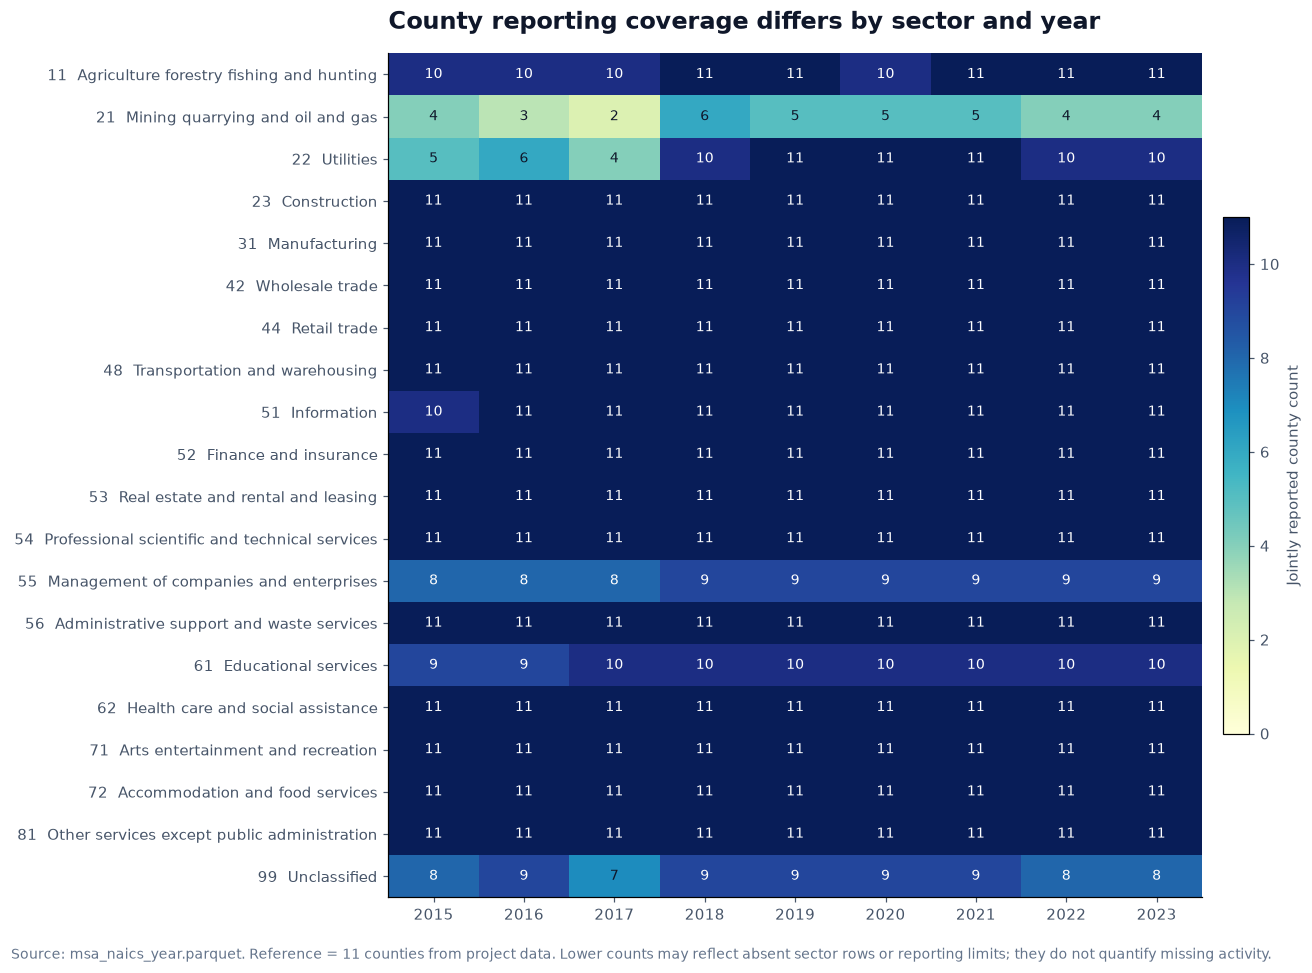

In [23]:
fig, ax = plt.subplots(figsize=(12, 8.6))
cov = coverage_n.sort_index()
im = ax.imshow(cov.to_numpy(dtype=float), cmap='YlGnBu', vmin=0, vmax=REFERENCE_COUNTIES, aspect='auto')
ax.set_yticks(range(len(cov)), [f'{c}  {NAICS_LABELS[c]}' for c in cov.index])
ax.set_xticks(range(len(cov.columns)), cov.columns)
for i in range(len(cov)):
    for j in range(len(cov.columns)):
        val = cov.iloc[i,j]
        if pd.notna(val):
            ax.text(j, i, f'{val:.0f}', ha='center', va='center', fontsize=9,
                    color='white' if val >= 8 else '#0f172a')
fig.colorbar(im, ax=ax, fraction=.03, pad=.025, label='Jointly reported county count')
ax.set_title('County reporting coverage differs by sector and year', loc='left', fontsize=16, pad=16)
fig.text(.01, -.02, 'Source: msa_naics_year.parquet. Reference = 11 counties from project data. Lower counts may reflect absent sector rows or reporting limits; they do not quantify missing activity.', fontsize=9, color='#64748b')
fig.tight_layout()
save_chart(fig, '12_naics_county_reporting_coverage.png')

## 9C Avoid confusing broad sectors with narrower CRE measures

The broad-sector counts below have different scope from the original CRE indicators.
An industry-coded business is not a property, project, or loan. Confirm exact upstream NAICS
definitions before performing a more detailed reconciliation between these series.

The original market file also has all-industry establishment size bands. These help describe
larger local operations, but cannot be assigned to a specific NAICS industry from this new file.
The derived 250+ band assumes the existing 20+ and 20–249 bands are nested, non-overlapping
at their stated boundaries and use identical definitions. These are **not** banking customer
segment definitions or counts of corporate borrowers.

In [24]:
scope_comparison = pd.DataFrame([
    ('Broad sector 53: real estate plus rental/leasing', ns.loc['53','cbp_establishments_count_latest']),
    ('Original narrower real estate CRE measure', charlotte.loc[NAICS_END_YEAR,'cre_real_estate_establishments_count']),
    ('Broad sector 23: all construction', ns.loc['23','cbp_establishments_count_latest']),
    ('Original nonresidential construction CRE measure', charlotte.loc[NAICS_END_YEAR,'cre_nonres_construction_establishments_count']),
], columns=['Scope', f'Business locations {NAICS_END_YEAR}'])
display(scope_comparison)
scope_comparison.to_csv(OUTPUT_DIR / 'tables/naics_and_cre_scope_comparison.csv', index=False)

size_columns = ['cbp_establishments_20plus_count', 'cbp_establishments_20_249_count']
if set(size_columns).issubset(raw_df.columns):
    aggregate_sizes = raw_df[raw_df['cbsa_code'].astype(str).eq(TARGET_CBSA)].set_index('year').loc[[NAICS_BASE_YEAR, NAICS_END_YEAR], size_columns].copy()
    aggregate_sizes['derived_establishments_250plus_count'] = aggregate_sizes['cbp_establishments_20plus_count'] - aggregate_sizes['cbp_establishments_20_249_count']
    assert aggregate_sizes['derived_establishments_250plus_count'].dropna().ge(0).all()
    display(Markdown('**All-industry location size context from the original market file, not industry-specific counts:**'))
    display(aggregate_sizes)
    aggregate_sizes.to_csv(OUTPUT_DIR / 'tables/charlotte_all_industry_size_context.csv')

interpretation = pd.DataFrame([
    ('Sector establishments', 'Potential location base to investigate', 'Locations are not unique firms or credit-qualified borrowers'),
    ('Establishment and job growth', 'Expansion that may create financing conversations', 'Does not identify external financing needs or existing lenders'),
    ('Employees per location', 'Average local operating scale', 'Not enterprise revenue, company headcount, or a corporate borrower count'),
    ('Annual payroll', 'Labor-payment flow and treasury discussion context', 'Not sales, profit, deposits, or measured debt demand'),
    ('Industry composition', 'Which business activities to investigate', 'Broad groups do not establish property type, credit risk, or strategic fit'),
    ('County count', 'Reporting diagnostic', 'Not an opportunity score or an independent denominator for each measure'),
], columns=['Measure', 'Useful lending interpretation', 'Boundary'])
display(interpretation)
interpretation.to_csv(OUTPUT_DIR / 'tables/naics_lending_indicator_interpretation.csv', index=False)

,Scope,Business locations 2023
0,Broad sector 53: real estate plus rental/leasing,"5,013.00"
1,Original narrower real estate CRE measure,"4,479.00"
2,Broad sector 23: all construction,"7,500.00"
3,Original nonresidential construction CRE measure,376.00


**All-industry location size context from the original market file, not industry-specific counts:**

,cbp_establishments_20plus_count,cbp_establishments_20_249_count,derived_establishments_250plus_count
year,,,
2019,"10,480.00","9,966.00",514.00
2023,"11,309.00","10,737.00",572.00


,Measure,Useful lending interpretation,Boundary
0,Sector establishments,Potential location base to investigate,Locations are not unique firms or credit-quali...
1,Establishment and job growth,Expansion that may create financing conversations,Does not identify external financing needs or ...
2,Employees per location,Average local operating scale,"Not enterprise revenue, company headcount, or ..."
3,Annual payroll,Labor-payment flow and treasury discussion con...,"Not sales, profit, deposits, or measured debt ..."
4,Industry composition,Which business activities to investigate,"Broad groups do not establish property type, c..."
5,County count,Reporting diagnostic,Not an opportunity score or an independent den...


In [27]:
transport = ns.loc['48']; manufacturing = ns.loc['31']; wholesale = ns.loc['42']
gap = reconciliation.loc[NAICS_END_YEAR]
naics_summary_text = f"""
### Added industry findings for Charlotte

The NAICS input contains {len(naics):,} rows, {naics['cbsa_code'].nunique()} CBSAs,
20 industry groups including unclassified, and years {naics['year'].min()}–{naics['year'].max()}.
Charlotte has {len(nc)} sector-year observations. No 2024 sector values are inferred.

- Transportation and warehousing has {transport['cbp_establishments_count_latest']:,.0f} locations
  and {transport['cbp_employment_count_latest']:,.0f} jobs in {NAICS_END_YEAR}. Locations grew
  {transport['cbp_establishments_count_growth_pct']:.1f}% and jobs grew
  {transport['cbp_employment_count_growth_pct']:.1f}% during {NAICS_BASE_YEAR}–{NAICS_END_YEAR}.
  Investigate fleet, equipment and working-capital needs with individual firms.
- Manufacturing has {manufacturing['cbp_employment_count_latest']:,.0f} jobs and averages
  {manufacturing['employees_per_location']:.1f} employees per location, providing operating-scale
  context. Job growth was {manufacturing['cbp_employment_count_growth_pct']:.1f}%.
- Wholesale trade locations declined {abs(wholesale['cbp_establishments_count_growth_pct']):.1f}%
  while employment grew {wholesale['cbp_employment_count_growth_pct']:.1f}%. Investigate existing
  operators; this pattern does not establish the cause or loan demand.
- The {NAICS_END_YEAR} sector sums are below the market-file totals by
  {gap['cbp_establishments_count_gap_market_minus_sectors']:,.0f} locations,
  {gap['cbp_employment_count_gap_market_minus_sectors']:,.0f} jobs, and
  ${gap['cbp_annual_payroll_usd_gap_market_minus_sectors']/1e6:,.3f} million in payroll.
  These residuals remain disclosed and are not filled.

### How to use the indicators

Use industry scale and growth to build and qualify a commercial prospect list. For corporate
opportunity, identify the parent enterprise, consolidated revenue, borrowing authority,
existing debt and financing plans. The local industry data are supporting context, not a count
of corporate borrowers. Employees-per-location averages and all-industry size bands cannot
prove demand for loans above $1 million. No loan-dollar forecast or attractiveness score is calculated.

Candidate industries illustrate different needs to test; they are not an optimized sector ranking.
Finance and insurance includes potential banking competitors and needs subsector filtering.
Management of companies has only nine jointly reported counties in 2023 and is not a count of
headquarters or unique parent companies. Broad construction and real estate/rental/leasing
are retained separately from the narrower CRE measures.
"""

display(Markdown(naics_summary_text))



### Added industry findings for Charlotte

The NAICS input contains 67,487 rows, 387 CBSAs,
20 industry groups including unclassified, and years 2015–2023.
Charlotte has 180 sector-year observations. No 2024 sector values are inferred.

- Transportation and warehousing has 2,680 locations
  and 77,790 jobs in 2023. Locations grew
  26.6% and jobs grew
  35.7% during 2019–2023.
  Investigate fleet, equipment and working-capital needs with individual firms.
- Manufacturing has 110,240 jobs and averages
  47.1 employees per location, providing operating-scale
  context. Job growth was 5.8%.
- Wholesale trade locations declined 3.8%
  while employment grew 7.4%. Investigate existing
  operators; this pattern does not establish the cause or loan demand.
- The 2023 sector sums are below the market-file totals by
  17 locations,
  904 jobs, and
  $83.655 million in payroll.
  These residuals remain disclosed and are not filled.

### How to use the indicators

Use industry scale and growth to build and qualify a commercial prospect list. For corporate
opportunity, identify the parent enterprise, consolidated revenue, borrowing authority,
existing debt and financing plans. The local industry data are supporting context, not a count
of corporate borrowers. Employees-per-location averages and all-industry size bands cannot
prove demand for loans above $1 million. No loan-dollar forecast or attractiveness score is calculated.

Candidate industries illustrate different needs to test; they are not an optimized sector ranking.
Finance and insurance includes potential banking competitors and needs subsector filtering.
Management of companies has only nine jointly reported counties in 2023 and is not a count of
headquarters or unique parent companies. Broad construction and real estate/rental/leasing
are retained separately from the narrower CRE measures.
